In [1]:
import numpy as np
import csv
import pandas as pd
from scipy.signal import find_peaks
#import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import cm
import matplotlib.patches as mpatches
import scipy as sp
import os
from pathlib import Path

from shapely.geometry.polygon import LinearRing, Polygon
from shapely.geometry import Point
from shapely.plotting import plot_polygon, plot_points
from shapely import symmetric_difference
# from shapely import affinity
# from descartes.patch import PolygonPatch

In [2]:
SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output/UMAP_stoch_figs/"))
if not os.path.exists(SAVEDIR):
    os.mkdir(SAVEDIR)

In [3]:
#UMAP stochastic
embedding_prot_erl_7_7_1_1 = pd.read_csv(str(SAVEDIR) + '/embedding_erl_4-9_1_1.csv',header=None)
embedding_prot_erl_7_7_2_1 = pd.read_csv(str(SAVEDIR) + '/embedding_erl_4-9_2_1.csv',header=None)
embedding_prot_erl_7_7_3_1 = pd.read_csv(str(SAVEDIR) + '/embedding_erl_4-9_3_1.csv',header=None)

#prot stochastic
all_prot_erl_7_7_1_1 = pd.read_csv(str(SAVEDIR) + '/all_prot_erl_4-9_1_1.csv',header=None)
all_prot_erl_7_7_2_1 = pd.read_csv(str(SAVEDIR) + '/all_prot_erl_4-9_2_1.csv',header=None)
all_prot_erl_7_7_3_1 = pd.read_csv(str(SAVEDIR) + '/all_prot_erl_4-9_3_1.csv',header=None)

In [4]:
#UMAP stochastic
embedding_prot_dmso_7_7_1_1 = pd.read_csv(str(SAVEDIR) + '/embedding_dmso_4-9_1_1.csv',header=None)
embedding_prot_dmso_7_7_2_1 = pd.read_csv(str(SAVEDIR) + '/embedding_dmso_4-9_2_1.csv',header=None)
embedding_prot_dmso_7_7_3_1 = pd.read_csv(str(SAVEDIR) + '/embedding_dmso_4-9_3_1.csv',header=None)

#prot stochastic
all_prot_dmso_7_7_1_1 = pd.read_csv(str(SAVEDIR) + '/all_prot_dmso_4-9_1_1.csv',header=None)
all_prot_dmso_7_7_2_1 = pd.read_csv(str(SAVEDIR) + '/all_prot_dmso_4-9_2_1.csv',header=None)
all_prot_dmso_7_7_3_1 = pd.read_csv(str(SAVEDIR) + '/all_prot_dmso_4-9_3_1.csv',header=None)

In [5]:
#times

all_time_stoch = pd.read_csv(str(SAVEDIR) + '/all_time_erl_4-9_1_1.csv',header=None)
all_time_at_stoch = pd.read_csv(str(SAVEDIR) + '/all_time_at_erl_4-9_1_1.csv',header=None)

In [6]:
embedding_tmp = np.loadtxt(str(SAVEDIR) + '/embedding_all_ode.csv', delimiter=',')
embedding_index = np.loadtxt(str(SAVEDIR) + '/embedding_all_ode_index.csv', delimiter=',')

In [7]:
window_size = len(all_prot_erl_7_7_3_1.columns)/18
cyce=int((window_size*11+window_size/2)-1)
cdc20=int((window_size*17+window_size/2)-1)

In [8]:
def restructProt(protDF, embedDF, timeDF):
    peaks_E, _ = find_peaks(protDF[cyce], prominence = 40/200, distance = 10)
    peaks_cdc, _ = find_peaks(protDF[cdc20], prominence = 40/200, distance = 10)
    
    mit_win = pd.DataFrame()
    time_win = pd.DataFrame()
    umap_win = pd.DataFrame()
    
    for n in range(2,len(peaks_cdc)-3):   #make sure we have divisions at ends 
        tmp_mit = peaks_cdc[n]
        tmp_mit2 = peaks_cdc[n+1]
        tmp_mit3 = peaks_cdc[n+2]
        tmp_mit4 = peaks_cdc[n+3]
        
        tmp_g1_s = peaks_E[(tmp_mit < peaks_E) & (peaks_E < tmp_mit2)]
        tmp_g1_s_2 = peaks_E[(tmp_mit2 < peaks_E) & (peaks_E < tmp_mit3)]
        tmp_g1_s_3 = peaks_E[(tmp_mit3 < peaks_E) & (peaks_E < tmp_mit4)]    
             
        if (np.size(tmp_g1_s) > 0) & (np.size(tmp_g1_s_2)>0) & (np.size(tmp_g1_s_3)>0):
            ordered = [tmp_mit, tmp_g1_s[0], tmp_mit2, tmp_g1_s_2[0], tmp_mit3, tmp_g1_s_3[0], tmp_mit4]
            g1_len_tmp = np.array(timeDF.iloc[ordered[3],0]) - np.array(timeDF.iloc[[ordered[2]],0])
            tmp_prot = protDF.iloc[int(ordered[1]):int(ordered[3]),:]
            tmp_umap = embedDF.iloc[int(ordered[1]):int(ordered[3]),:]
            tmp_time = timeDF.iloc[int(ordered[1]):int(ordered[3]),:]
            tmp = [g1_len_tmp]*len(tmp_time)
            tmp = np.concatenate(tmp, axis=0)
            tmp_time.insert(1, 'G1', tmp)
            
            mit_win = pd.concat([mit_win,tmp_prot],ignore_index=True)
            time_win = pd.concat([time_win, tmp_time], ignore_index=True)
            umap_win = pd.concat([umap_win, tmp_umap], ignore_index=True)
            
    return mit_win, time_win, umap_win

In [9]:
def splitIMT(protDF, embedDF, timeDF):
    peaks_E, _ = find_peaks(protDF[cyce], prominence = 40/200, distance = 10)
    peaks_cdc, _ = find_peaks(protDF[cdc20], prominence = 40/200, distance = 10)
    
    mit_win = []
    time_win = pd.DataFrame()
    umap_win = []
    count = 0
    for n in range(2,len(peaks_cdc)-3):   #make sure we have divisions at ends 
        tmp_mit = peaks_cdc[n]
        tmp_mit2 = peaks_cdc[n+1]
        tmp_mit3 = peaks_cdc[n+2]
        tmp_mit4 = peaks_cdc[n+3]
        
        tmp_g1_s = peaks_E[(tmp_mit < peaks_E) & (peaks_E < tmp_mit2)]
        tmp_g1_s_2 = peaks_E[(tmp_mit2 < peaks_E) & (peaks_E < tmp_mit3)]
        tmp_g1_s_3 = peaks_E[(tmp_mit3 < peaks_E) & (peaks_E < tmp_mit4)]    
             
        if (np.size(tmp_g1_s) > 0) & (np.size(tmp_g1_s_2)>0) & (np.size(tmp_g1_s_3)>0):
            ordered = [tmp_mit, tmp_g1_s[0], tmp_mit2, tmp_g1_s_2[0], tmp_mit3, tmp_g1_s_3[0], tmp_mit4]
            g1_len_tmp = np.array(timeDF.iloc[ordered[3],0]) - np.array(timeDF.iloc[[ordered[2]],0])
            tmp_prot = protDF.iloc[int(ordered[2]):int(ordered[4]),:]
            tmp_arr = tmp_prot.to_numpy()
            tmp_umap = embedDF.iloc[int(ordered[2]):int(ordered[4]),:]
            tmp_umap_arr = tmp_umap.to_numpy()
            tmp_time = timeDF.iloc[int(ordered[2]):int(ordered[4]),:]
            tmp = [g1_len_tmp]*len(tmp_time)
            tmp = np.concatenate(tmp, axis=0)
            tmp_time.insert(1, 'G1', tmp)
            
            mit_win = [mit_win, tmp_arr]
            time_win = pd.concat([time_win, tmp_time], ignore_index=True)
            if len(umap_win)==0:
                umap_win = [tmp_umap_arr]
            else:
                umap_win.append(tmp_umap_arr)
            count += 1
    return tmp_arr, time_win, umap_win, count

In [10]:
mit_win_erl_1_1, time_win_erl_1_1, umap_win_erl_1_1 = restructProt(all_prot_erl_7_7_1_1, embedding_prot_erl_7_7_1_1, all_time_at_stoch)
mit_win_erl_2_1, time_win_erl_2_1, umap_win_erl_2_1 = restructProt(all_prot_erl_7_7_2_1, embedding_prot_erl_7_7_2_1, all_time_at_stoch)
mit_win_erl_3_1, time_win_erl_3_1, umap_win_erl_3_1 = restructProt(all_prot_erl_7_7_3_1, embedding_prot_erl_7_7_3_1, all_time_at_stoch)

In [11]:
mit_all_erl_1_1, test1, umap_all_erl_1_1, count = splitIMT(all_prot_erl_7_7_1_1, embedding_prot_erl_7_7_1_1, all_time_at_stoch)
mit_all_erl_2_1, test2, umap_all_erl_2_1, count = splitIMT(all_prot_erl_7_7_2_1, embedding_prot_erl_7_7_2_1, all_time_at_stoch)
mit_all_erl_3_1, test3, umap_all_erl_3_1, count = splitIMT(all_prot_erl_7_7_3_1, embedding_prot_erl_7_7_3_1, all_time_at_stoch)

In [12]:
mit_win_dmso_1_1, time_win_dmso_1_1, umap_win_dmso_1_1 = restructProt(all_prot_dmso_7_7_1_1, embedding_prot_dmso_7_7_1_1, all_time_at_stoch)
mit_win_dmso_2_1, time_win_dmso_2_1, umap_win_dmso_2_1 = restructProt(all_prot_dmso_7_7_2_1, embedding_prot_dmso_7_7_2_1, all_time_at_stoch)
mit_win_dmso_3_1, time_win_dmso_3_1, umap_win_dmso_3_1 = restructProt(all_prot_dmso_7_7_3_1, embedding_prot_dmso_7_7_3_1, all_time_at_stoch)

# Polygon Method Analysis

### DMSO

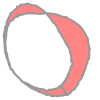

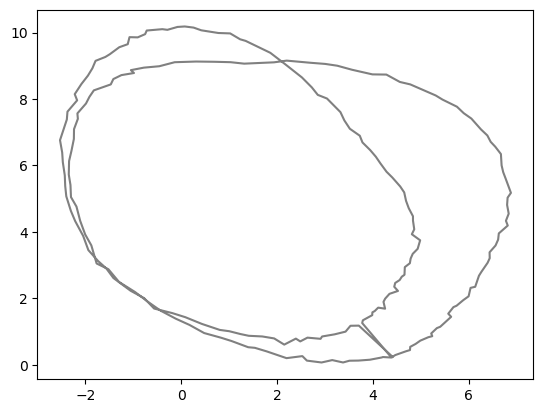

In [13]:
# DMSO polygon - original w/o expansion

# Find the two boundaries of the UMAP space that outline the ROI
ind = np.where(embedding_index == 1001)
x = np.ndarray.tolist(embedding_tmp[ind,0])
y = np.ndarray.tolist(embedding_tmp[ind,1])  
boundary1 = list(zip(x[0][int(len(x[0])/2):],y[0][int(len(x[0])/2):]))

ind = np.where(embedding_index == 2000)
x = np.ndarray.tolist(embedding_tmp[ind,0])
y = np.ndarray.tolist(embedding_tmp[ind,1])
boundary2 = list(zip(x[0][int(len(x[0])/2):],y[0][int(len(x[0])/2):]))

# Combine the boundaries
full_boundary = boundary1 + boundary2
full_boundary = tuple(map(tuple,full_boundary)) # Transform into tuple

# Create a filling polygon
DMSO_poly = Polygon(full_boundary)

# Check if the polygon contains a point
# point=Point(5,5)
# print(DMSO_poly.contains(point))
# point=Point(6,2)
# print(DMSO_poly.contains(point))

plt.plot(*DMSO_poly.exterior.xy, color = 'gray')
DMSO_poly

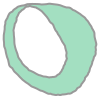

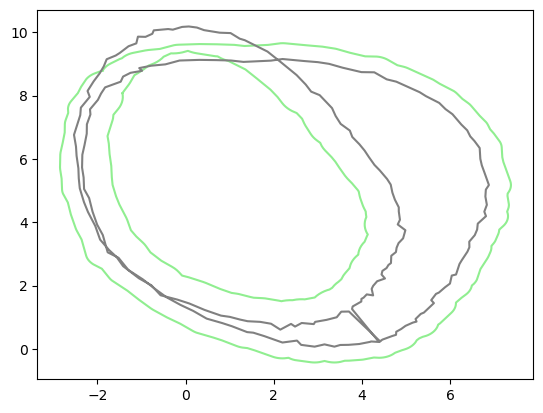

In [14]:
# DMSO polygon - with expansion

bound1_expand1 = Polygon(boundary1).buffer(0.5)
bound2_expand1 = Polygon(boundary2).buffer(-0.75)

DMSO_polyexp = symmetric_difference(bound1_expand1,bound2_expand1)

fig = plt.figure()
plt.plot(*bound1_expand1.exterior.xy, color = 'lightgreen')
plt.plot(*bound2_expand1.exterior.xy, color = 'lightgreen')
plt.plot(*DMSO_poly.exterior.xy, color = 'gray')

DMSO_polyexp

### ERL Slow

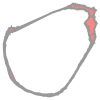

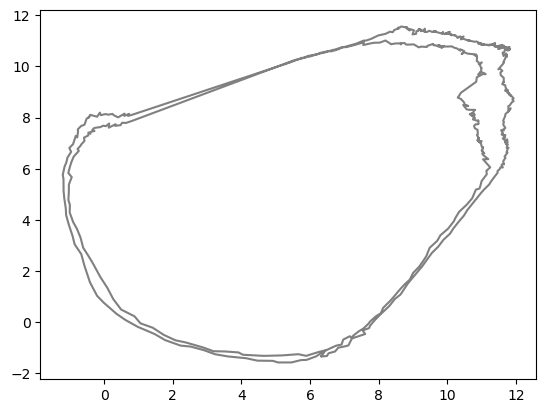

In [15]:
# ERL slow polygon - original w/o expansion

# Find the two boundaries of the UMAP space that outline the ROI
ind = np.where(embedding_index == 1)
x = np.ndarray.tolist(embedding_tmp[ind,0])
y = np.ndarray.tolist(embedding_tmp[ind,1])  
boundary1 = list(zip(x[0][int(len(x[0])/2):],y[0][int(len(x[0])/2):]))

ind = np.where(embedding_index == 112)
x = np.ndarray.tolist(embedding_tmp[ind,0])
y = np.ndarray.tolist(embedding_tmp[ind,1])
boundary2 = list(zip(x[0][int(len(x[0])/2):],y[0][int(len(x[0])/2):]))

# Combine the boundaries
full_boundary = boundary1 + boundary2
full_boundary = tuple(map(tuple,full_boundary)) # Transform into tuple

# Create filling Polygon
ERL_slow_poly = Polygon(full_boundary)

# Check if the polygon contains a point
# point=Point(11,9)
# print(ERL_slow_poly.contains(point))
# point=Point(6,2)
# print(ERL_slow_poly.contains(point))

plt.plot(*ERL_slow_poly.exterior.xy, color = 'gray')
ERL_slow_poly

'MultiPolygon'

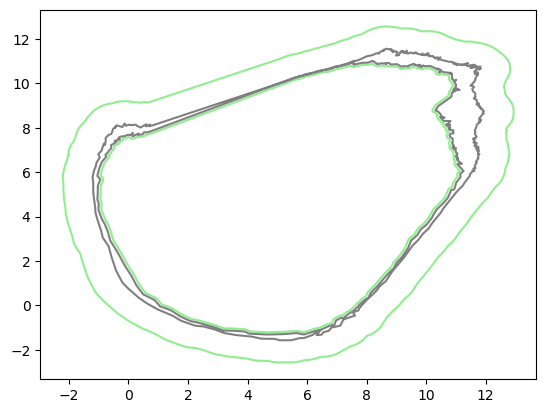

In [16]:
# ERL slow polygon - with expansion

bound1_expand2 = Polygon(boundary1).buffer(1)
bound2_expand2 = Polygon(boundary2).buffer(-0.1)

ERLslow_polyexp = symmetric_difference(bound1_expand2,bound2_expand2)

fig = plt.figure()
plt.plot(*bound1_expand2.exterior.xy, color = 'lightgreen')
plt.plot(*bound2_expand2.exterior.xy, color = 'lightgreen')
plt.plot(*ERL_slow_poly.exterior.xy, color = 'gray')

ERLslow_polyexp.geom_type

### ERL Fast

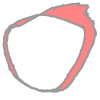

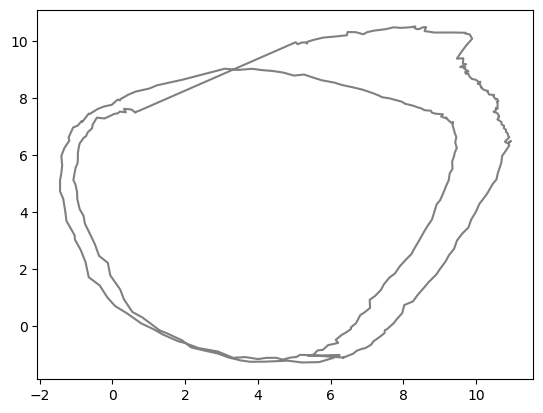

In [17]:
# ERL fast polygon - original w/o expansion

# Find the two boundaries of the UMAP space that outline the ROI
ind = np.where(embedding_index == 114)
x = np.ndarray.tolist(embedding_tmp[ind,0])
y = np.ndarray.tolist(embedding_tmp[ind,1])  
boundary1 = list(zip(x[0][int(len(x[0])/2):],y[0][int(len(x[0])/2):]))

ind = np.where(embedding_index == 1000)
x = np.ndarray.tolist(embedding_tmp[ind,0])
y = np.ndarray.tolist(embedding_tmp[ind,1])
boundary2 = list(zip(x[0][int(len(x[0])/2):],y[0][int(len(x[0])/2):]))

# Combine the boundaries
full_boundary = boundary1 + boundary2
full_boundary = tuple(map(tuple,full_boundary)) # Transform into tuple

# Create filling Polygon
ERL_fast_poly = Polygon(full_boundary)

# Check if the polygon contains a point
# point=Point(9,4)
# print(ERL_fast_poly.contains(point))
# point=Point(6,2)
# print(ERL_fast_poly.contains(point))

plt.plot(*ERL_fast_poly.exterior.xy, color = 'gray')
ERL_fast_poly

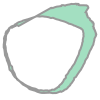

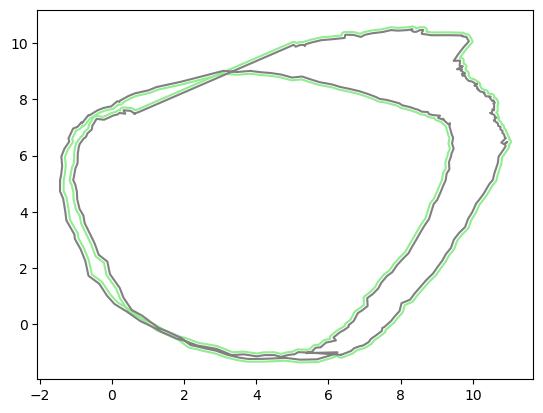

In [18]:
# ERL fast polygon - with expansion

bound1_expand3 = Polygon(boundary1).buffer(0.1)
bound2_expand3 = Polygon(boundary2).buffer(-0.1)

ERLfast_polyexp = symmetric_difference(bound1_expand3, bound2_expand3)

fig = plt.figure()
plt.plot(*bound1_expand3.exterior.xy, color = 'lightgreen')
plt.plot(*bound2_expand3.exterior.xy, color = 'lightgreen')
plt.plot(*ERL_fast_poly.exterior.xy, color = 'gray')

ERLfast_polyexp

### Plot Regions

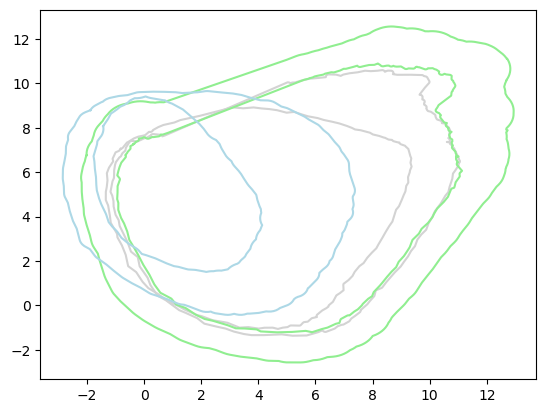

In [19]:
fig = plt.figure()
plt.plot(*bound1_expand3.exterior.xy, color = 'lightgray')
plt.plot(*bound2_expand3.exterior.xy, color = 'lightgray')
plt.plot(*bound1_expand2.exterior.xy, color = 'lightgreen')
plt.plot(*bound2_expand2.exterior.xy, color = 'lightgreen')
plt.plot(*bound1_expand1.exterior.xy, color = 'lightblue')
plt.plot(*bound2_expand1.exterior.xy, color = 'lightblue')

### Classification

In [32]:
def plot_by_class(UMAP_vals):
    fig = plt.figure()
    erl_slow = 0
    erl_fast = 0
    dmso = 0
    
    perc_not_counted = []
    
    xmin, xmax = -5, 15
    ymin, ymax = -5, 15
    ind = np.where(embedding_index == 1) 
    x=np.ndarray.tolist(embedding_tmp[ind,0])
    y=np.ndarray.tolist(embedding_tmp[ind,1])

    
    
    # Define DMSO Region
    ind = np.where(embedding_index == 1001)
    x = np.ndarray.tolist(embedding_tmp[ind,0])
    y = np.ndarray.tolist(embedding_tmp[ind,1])  
    boundary1 = list(zip(x[0][int(len(x[0])/2):],y[0][int(len(x[0])/2):]))

    ind = np.where(embedding_index == 2000)
    x = np.ndarray.tolist(embedding_tmp[ind,0])
    y = np.ndarray.tolist(embedding_tmp[ind,1])
    boundary2 = list(zip(x[0][int(len(x[0])/2):],y[0][int(len(x[0])/2):]))

    full_boundary = boundary1 + boundary2
    full_boundary = tuple(map(tuple,full_boundary)) # Transform into tuple

    poly1 = Polygon(full_boundary)    # Create filling Polygon

    dmso_plot = mpatches.Patch(color='lightblue')
    
    # DMSO polygon - with expansion

    bound1_expand1 = Polygon(boundary1).buffer(1)
    bound2_expand1 = Polygon(boundary2).buffer(-0.75)

    DMSO_polyexp = symmetric_difference(bound1_expand1,bound2_expand1)
    plt.plot(*bound1_expand1.exterior.xy, color = 'lightblue')
    plt.plot(*bound2_expand1.exterior.xy, color = 'lightblue')
    
    

    
    # Define ERL Slow Region
    ind = np.where(embedding_index == 1)
    x = np.ndarray.tolist(embedding_tmp[ind,0])
    y = np.ndarray.tolist(embedding_tmp[ind,1])  
    boundary1 = list(zip(x[0][int(len(x[0])/2):],y[0][int(len(x[0])/2):]))

    ind = np.where(embedding_index == 112)
    x = np.ndarray.tolist(embedding_tmp[ind,0])
    y = np.ndarray.tolist(embedding_tmp[ind,1])
    boundary2 = list(zip(x[0][int(len(x[0])/2):],y[0][int(len(x[0])/2):]))

    full_boundary = boundary1 + boundary2
    full_boundary = tuple(map(tuple,full_boundary)) # Transform into tuple

    poly2 = Polygon(full_boundary)    # Create filling Polygon

    erl_slow_plot = mpatches.Patch(color='lightgreen')
    
    # ERL slow polygon - with expansion

    bound1_expand2 = Polygon(boundary1).buffer(1)
    bound2_expand2 = Polygon(boundary2).buffer(-0.1)

    ERLslow_polyexp = symmetric_difference(bound1_expand2,bound2_expand2)
    plt.plot(*bound1_expand2.exterior.xy, color = 'lightgreen')
    plt.plot(*bound2_expand2.exterior.xy, color = 'lightgreen')
    



    # Define ERL Fast Region
    
    ind = np.where(embedding_index == 114)
    x = np.ndarray.tolist(embedding_tmp[ind,0])
    y = np.ndarray.tolist(embedding_tmp[ind,1])  
    boundary1 = list(zip(x[0][int(len(x[0])/2):],y[0][int(len(x[0])/2):]))

    ind = np.where(embedding_index == 1000)
    x = np.ndarray.tolist(embedding_tmp[ind,0])
    y = np.ndarray.tolist(embedding_tmp[ind,1])
    boundary2 = list(zip(x[0][int(len(x[0])/2):],y[0][int(len(x[0])/2):]))

    full_boundary = boundary1 + boundary2
    full_boundary = tuple(map(tuple,full_boundary)) # Transform into tuple

    poly3 = Polygon(full_boundary)    # Create filling Polygon

    erl_fast_plot = mpatches.Patch(color='lightgrey')
    
    # ERL fast polygon - with expansion

    bound1_expand3 = Polygon(boundary1).buffer(0.1)
    bound2_expand3 = Polygon(boundary2).buffer(-0.1)

    ERLfast_polyexp = symmetric_difference(bound1_expand3, bound2_expand3)
    
    plt.plot(*bound1_expand3.exterior.xy, color = 'lightgray')
    plt.plot(*bound2_expand3.exterior.xy, color = 'lightgray')


    # Classify trajectories
    dmso_num = []
    erl_slow_num = []
    erl_fast_num = []
    pts_out_num = []
    each_traj_perc = []
    
    for num in range(len(UMAP_vals)):
        
        erl_slow_count = 0
        erl_fast_count = 0
        dmso_count = 0
        num_pts_outside = 0
        
        for val in range(len(UMAP_vals[num])): 
            point = Point(UMAP_vals[num][val])
            if (DMSO_polyexp.contains(point) & ERLslow_polyexp.contains(point) & ERLfast_polyexp.contains(point)):
                dmso_count += 1
                erl_slow_count += 1
                erl_fast_count += 1
            elif (ERLslow_polyexp.contains(point) & ERLfast_polyexp.contains(point)):
                erl_slow_count += 1
                erl_fast_count += 1
            elif (DMSO_polyexp.contains(point) & ERLslow_polyexp.contains(point)):
                dmso_count += 1
                erl_slow_count += 1
            elif (DMSO_polyexp.contains(point) & ERLfast_polyexp.contains(point)):
                dmso_count += 1
                erl_fast_count += 1
            elif (DMSO_polyexp.contains(point)):
                dmso_count += 1
            elif (ERLslow_polyexp.contains(point)):
                erl_slow_count += 1
            elif (ERLfast_polyexp.contains(point)):
                erl_fast_count += 1
            else:
                num_pts_outside += 1
            
        # save counts
        dmso_num.append(dmso_count)
        erl_slow_num.append(erl_slow_count)
        erl_fast_num.append(erl_fast_count)
        pts_out_num.append(num_pts_outside)
        
        
        # percent of point in each class
        traj_class = [erl_slow_count, erl_fast_count, dmso_count, num_pts_outside]
        point_total = erl_slow_count + erl_fast_count + dmso_count + num_pts_outside
        traj_perc = [(x/point_total)*100 for x in traj_class]
        
        # save for each trajectory
        each_traj_perc.append(traj_perc)
        
        # percentage of points outside regions 
        if (num == 0):
            perc_not_counted = [round((num_pts_outside/point_total)*100,2)]
        else:
            perc_not_counted.append(round((num_pts_outside/point_total)*100,2))
        
        
        # use percentage to designate class
        if ((round(traj_perc[0],2) > round(traj_perc[1],2)) & (round(traj_perc[0],2) > round(traj_perc[2],2))):
            color='darkgreen'
            erl_slow += 1
        elif ((round(traj_perc[2],2) > round(traj_perc[0],2)) & (round(traj_perc[2],2) > round(traj_perc[1],2))):
            color='darkblue'
            dmso += 1
        else:
            color='dimgrey'
            erl_fast += 1
                
            
        plt.plot(UMAP_vals[num][:,0], UMAP_vals[num][:,1], c=color, lw=0.3)
        classes = [erl_slow, erl_fast, dmso]
        total = erl_slow + erl_fast + dmso
        perc = [(x/total)*100 for x in classes]
        
        plt.xlim([xmin, xmax])
        plt.ylim([ymin, ymax])
        plt.xticks([-5, 0, 5, 10])
        plt.yticks([-5, 0, 5, 10])
    
        plt.legend([dmso_plot, erl_fast_plot, erl_slow_plot], 
                    (f'+DMSO: {round(perc[2],2)}%', f'+ERL fast: {round(perc[1],2)}%', f'+ERL slow: {round(perc[0],2)}%'), 
                    loc=2, fontsize=8)
        
        '+DMSO, ODE' '+ERL, ODE'
        
            
    return classes, perc_not_counted, dmso_num, erl_slow_num, erl_fast_num, pts_out_num, each_traj_perc, perc

## Low Stiffness Results

### UMAP Plot

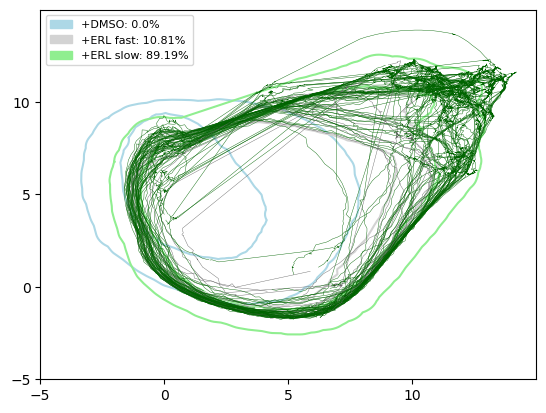

In [33]:
result_lowstiff = plot_by_class(umap_all_erl_1_1)

### Stacked Bar Plot: Distribution of Points for Each Trajectory

##### Number of Points; Unordered

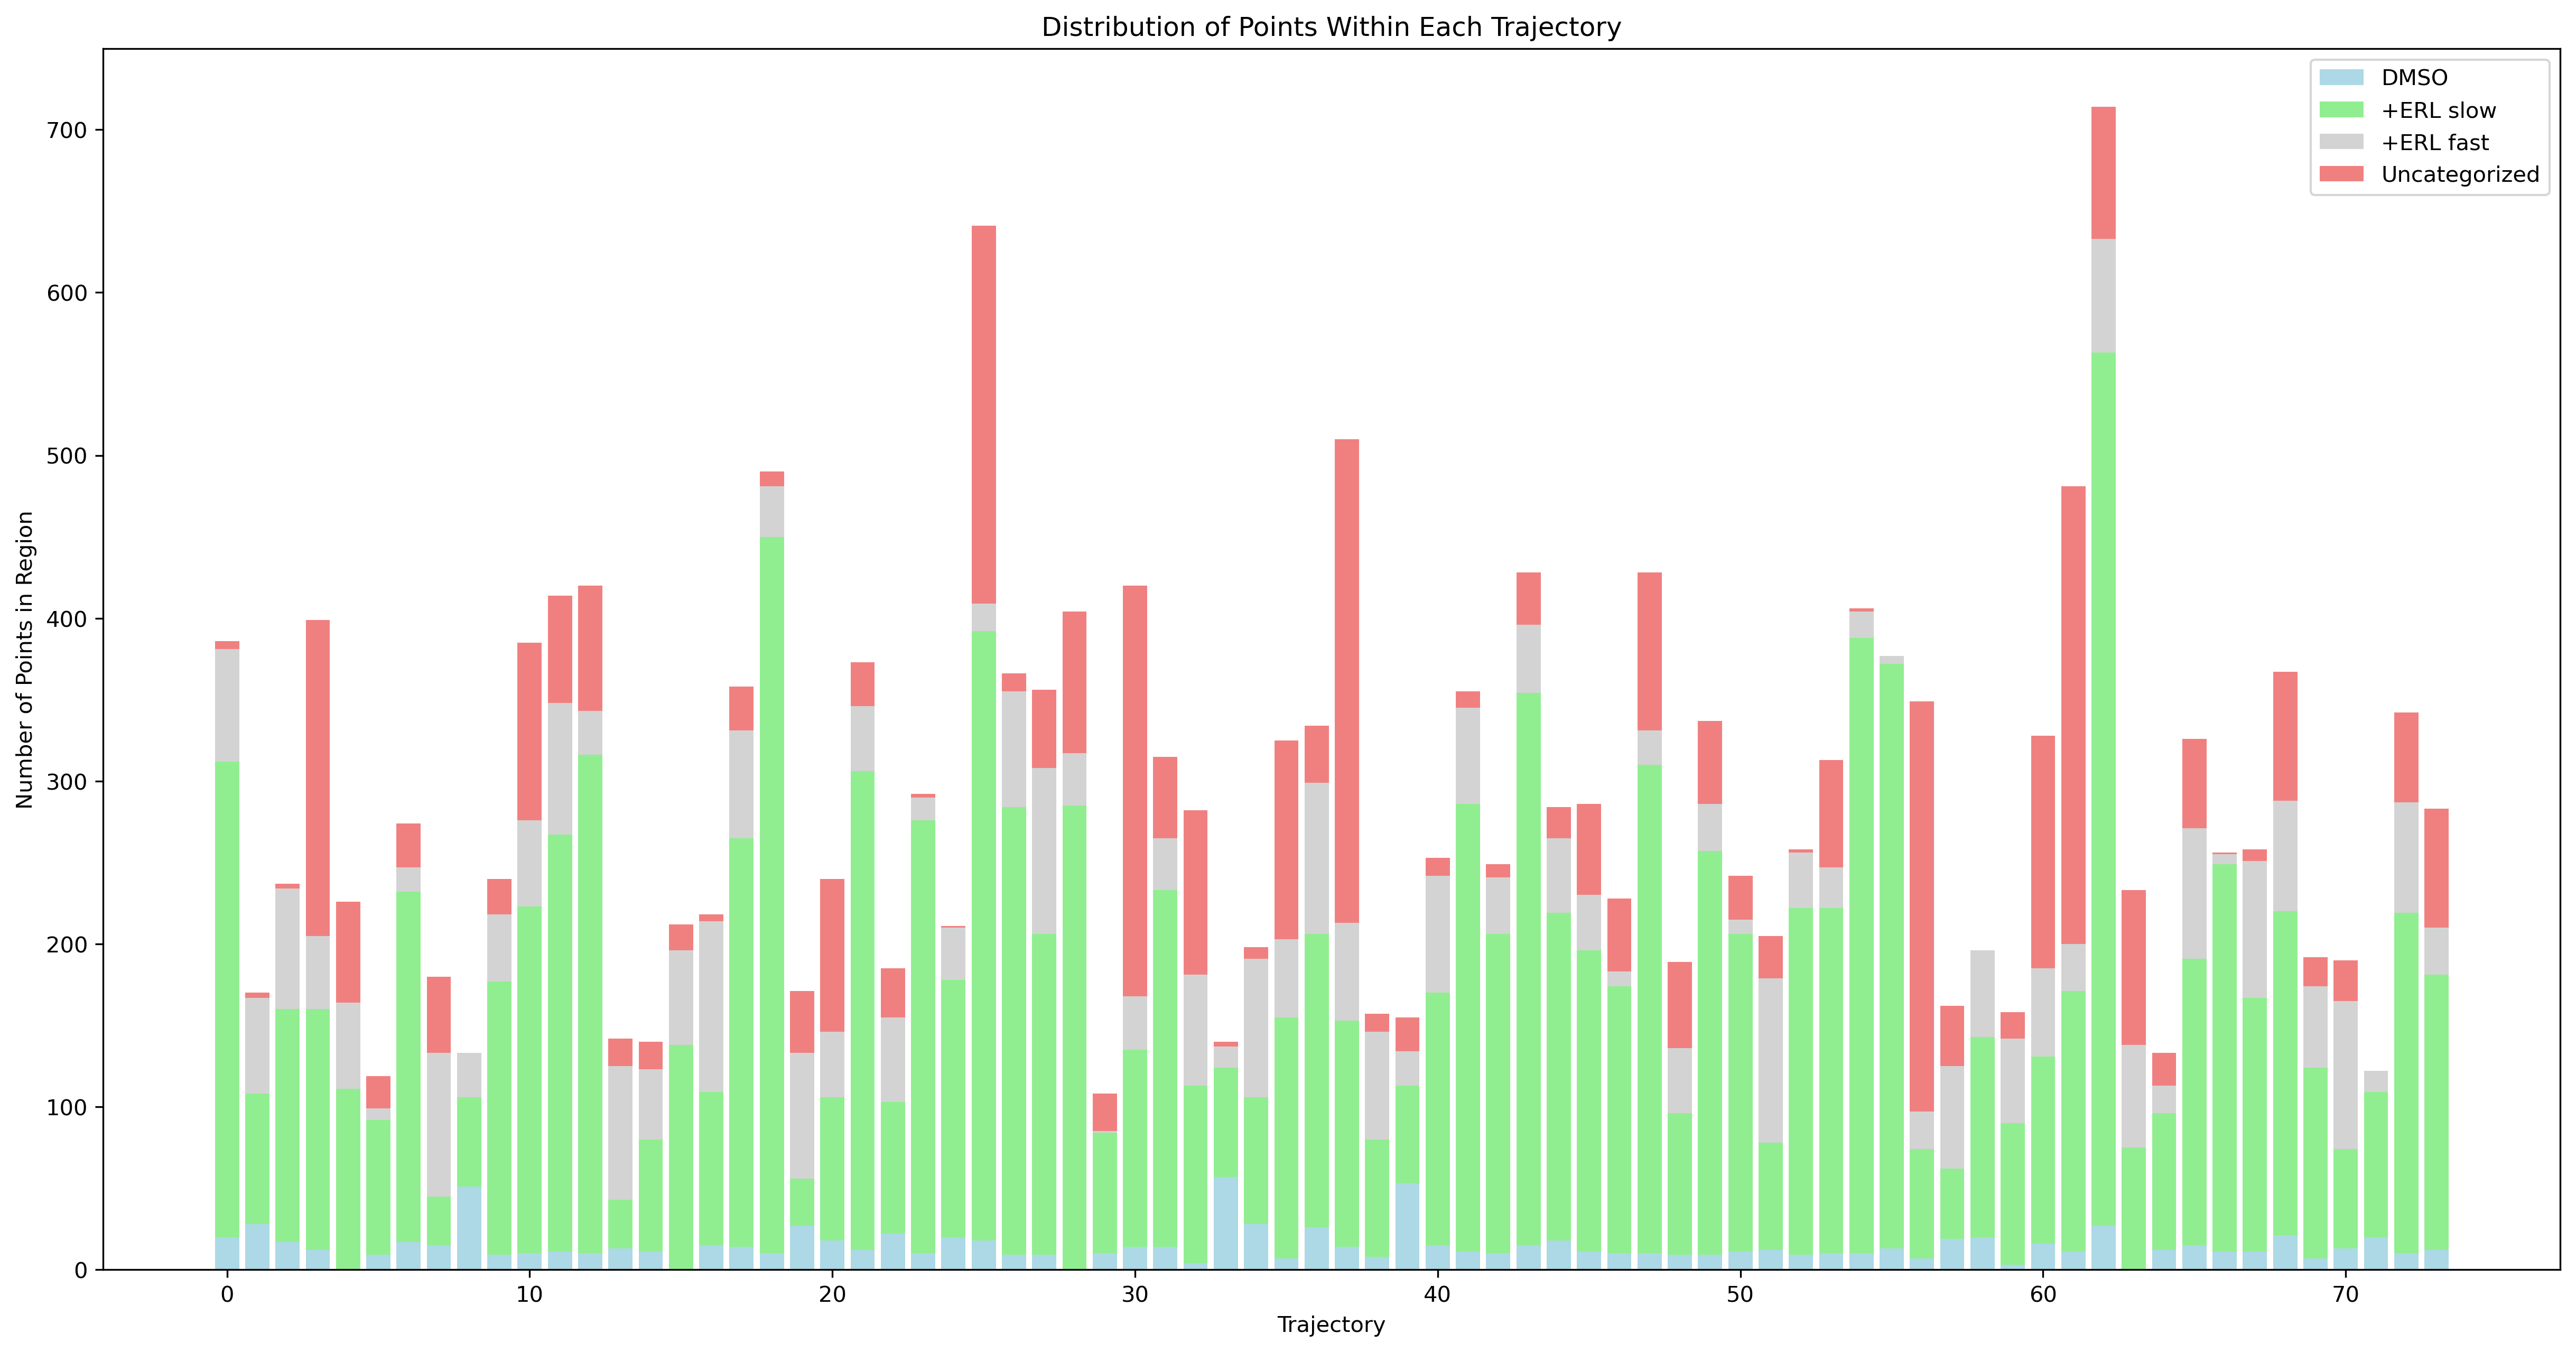

In [24]:
plt.figure(figsize=(20,10),dpi=300)

# create data
x = np.arange(sum(result_lowstiff[0]))

y1 = np.array(result_lowstiff[2])
y2 = np.array(result_lowstiff[3])
y3 = np.array(result_lowstiff[4])
y4 = np.array(result_lowstiff[5])
 
# plot bars in stack manner
plt.bar(x, y1, color='lightblue')
plt.bar(x, y2, bottom=y1, color='lightgreen')
plt.bar(x, y3, bottom=y1+y2, color='lightgrey')
plt.bar(x, y4, bottom=y1+y2+y3, color='lightcoral')

plt.xlabel("Trajectory")
plt.ylabel("Number of Points in Region")
plt.legend(["DMSO", "+ERL slow", "+ERL fast", "Uncategorized"],)

# plt.legend([dmso_plot, erl_fast_plot, erl_slow_plot], 
#                     (f'+DMSO: {round(perc[2],2)}%', f'+ERL fast: {round(perc[1],2)}%', f'+ERL slow: {round(perc[0],2)}%'), 
#                     loc=2, fontsize=8)


plt.title("Distribution of Points Within Each Trajectory")
plt.show()

##### Percentage of Points; Ordered by +ERL slow

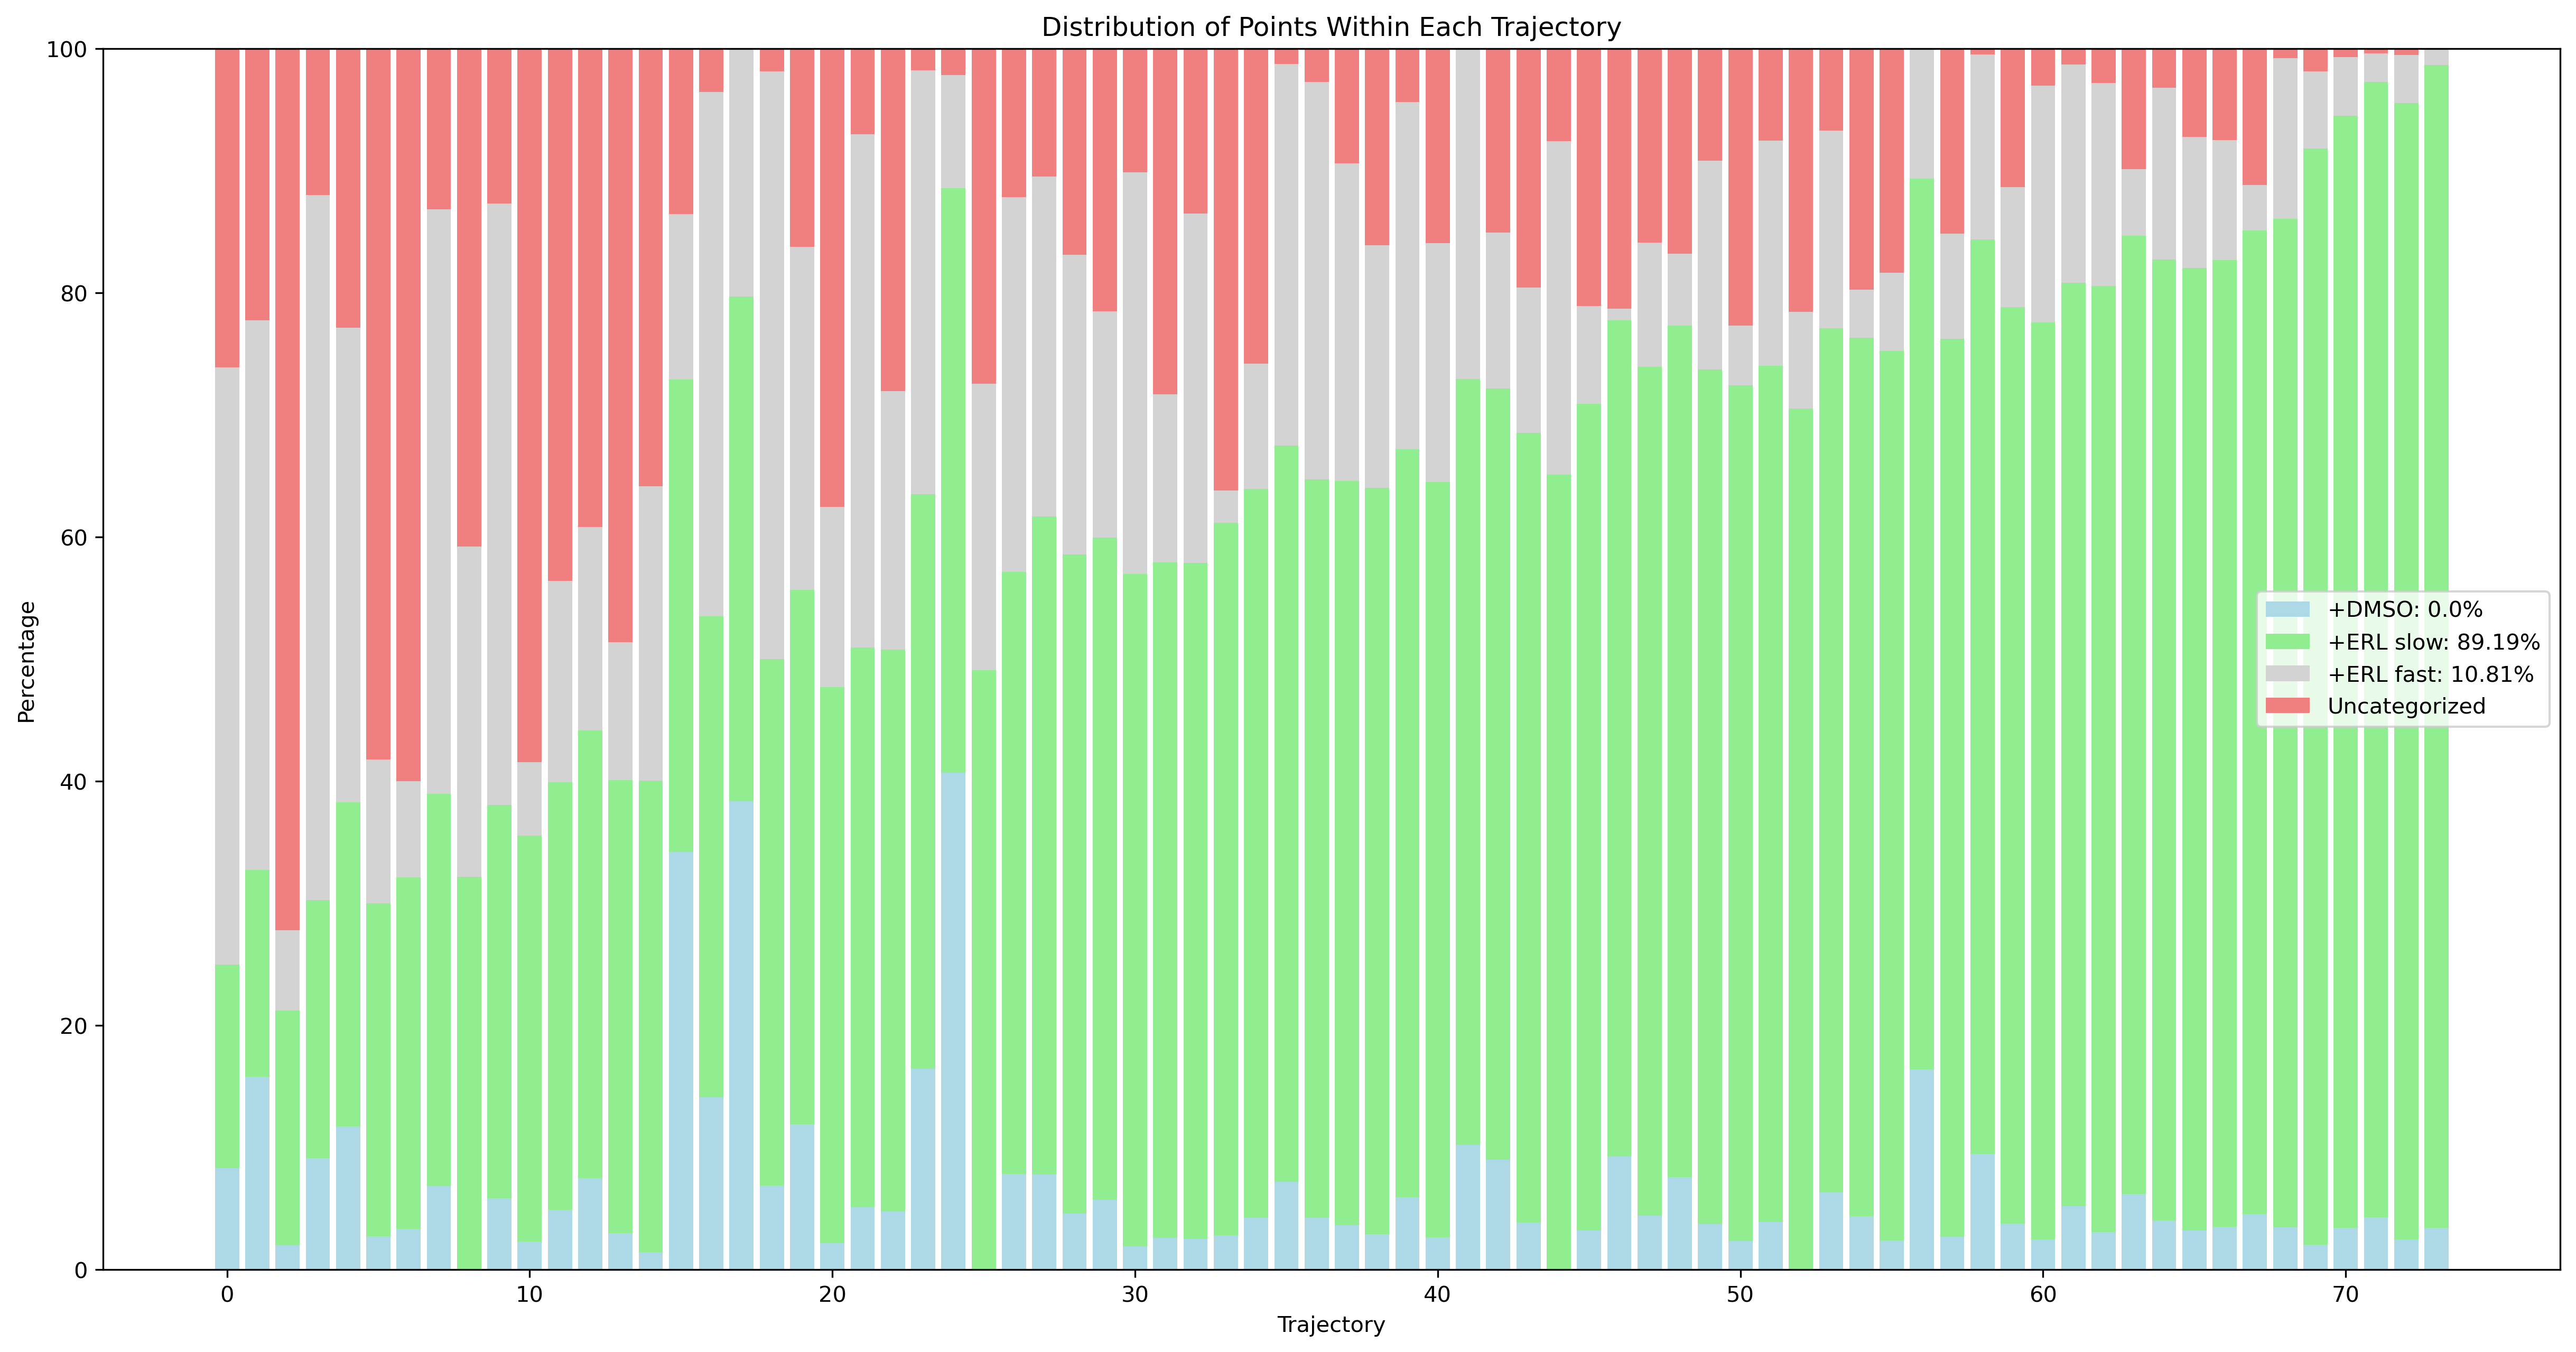

In [78]:
plt.figure(figsize=(20,10),dpi=300)

# create data
x = np.arange(sum(result_lowstiff[0]))

y1 = np.zeros(len(result_lowstiff[6]))
y2 = np.zeros(len(result_lowstiff[6]))
y3 = np.zeros(len(result_lowstiff[6]))
y4 = np.zeros(len(result_lowstiff[6]))

for i in range(len(result_lowstiff[6])):
    y1[i] = result_lowstiff[6][i][2]
    y2[i] = result_lowstiff[6][i][0]
    y3[i] = result_lowstiff[6][i][1]
    y4[i] = result_lowstiff[6][i][3]
    
inds = y2.argsort()
y1_sort = y1[inds]
y2_sort = y2[inds]
y3_sort = y3[inds]
y4_sort = y4[inds]
    
# plot bars in stack manner

plt.bar(x, y1_sort, color='lightblue')
plt.bar(x, y2_sort, bottom=y1_sort, color='lightgreen')
plt.bar(x, y3_sort, bottom=y1_sort+y2_sort, color='lightgrey')
plt.bar(x, y4_sort, bottom=y1_sort+y2_sort+y3_sort, color='lightcoral')

plt.xlabel("Trajectory")
plt.ylabel("Percentage")
plt.legend([f"+DMSO: {round(result_lowstiff[7][2],2)}%", f"+ERL slow: {round(result_lowstiff[7][0],2)}%", 
            f"+ERL fast: {round(result_lowstiff[7][1],2)}%", "Uncategorized"])

plt.title("Distribution of Points Within Each Trajectory")
plt.show()

### Histogram: How many trajectories have a certain percentage of point left uncategorized?

In [131]:
# plt.hist(result_lowstiff[1])
# plt.xlabel('Percentage of Points Uncategorized')
# plt.ylabel('Number of Trajectories')

## Intermediate Stiffness Results

### UMAP Plot

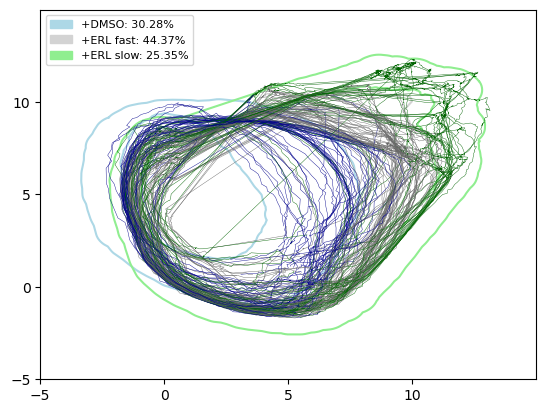

In [79]:
result_intstiff = plot_by_class(umap_all_erl_2_1)

### Stacked Bar Plot: Distribution of Points for Each Trajectory

##### Number of Points; Unordered

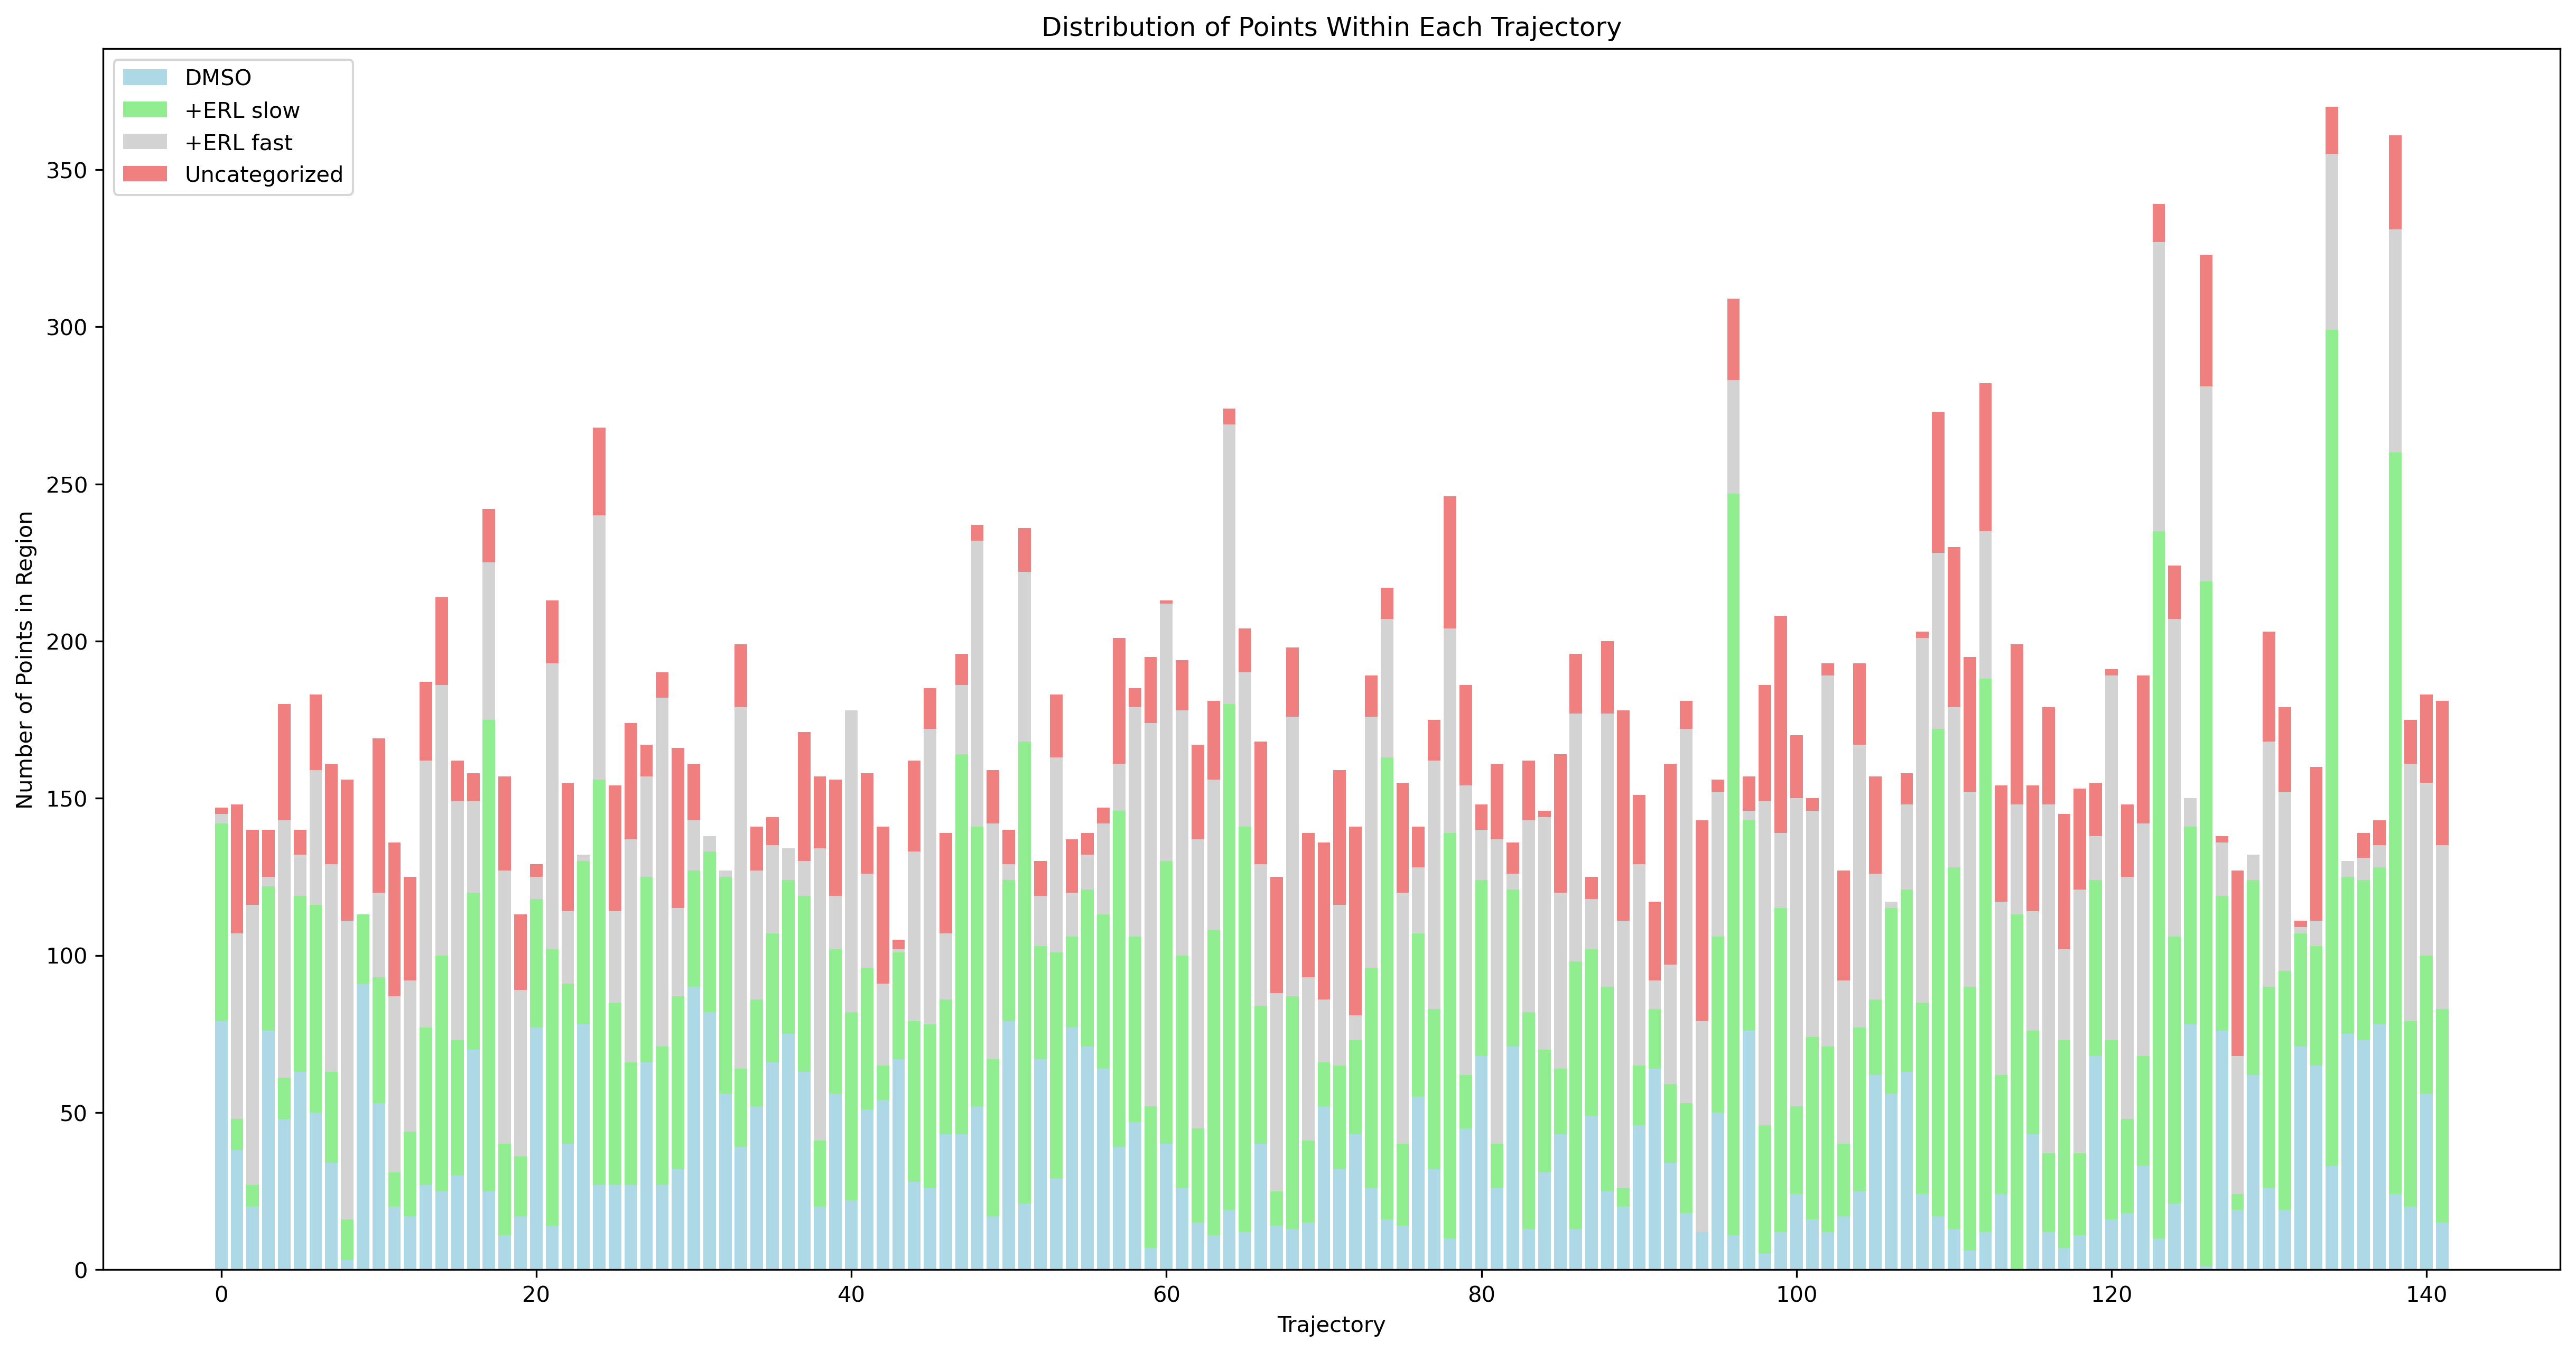

In [81]:
plt.figure(figsize=(20,10),dpi=300)

# create data
x = np.arange(sum(result_intstiff[0]))

y1 = np.array(result_intstiff[2])
y2 = np.array(result_intstiff[3])
y3 = np.array(result_intstiff[4])
y4 = np.array(result_intstiff[5])
 
# plot bars in stack manner
plt.bar(x, y1, color='lightblue')
plt.bar(x, y2, bottom=y1, color='lightgreen')
plt.bar(x, y3, bottom=y1+y2, color='lightgrey')
plt.bar(x, y4, bottom=y1+y2+y3, color='lightcoral')

plt.xlabel("Trajectory")
plt.ylabel("Number of Points in Region")
plt.legend(["DMSO", "+ERL slow", "+ERL fast", "Uncategorized"])
plt.title("Distribution of Points Within Each Trajectory")
plt.show()

##### Percentage of Points; Ordered by +DMSO

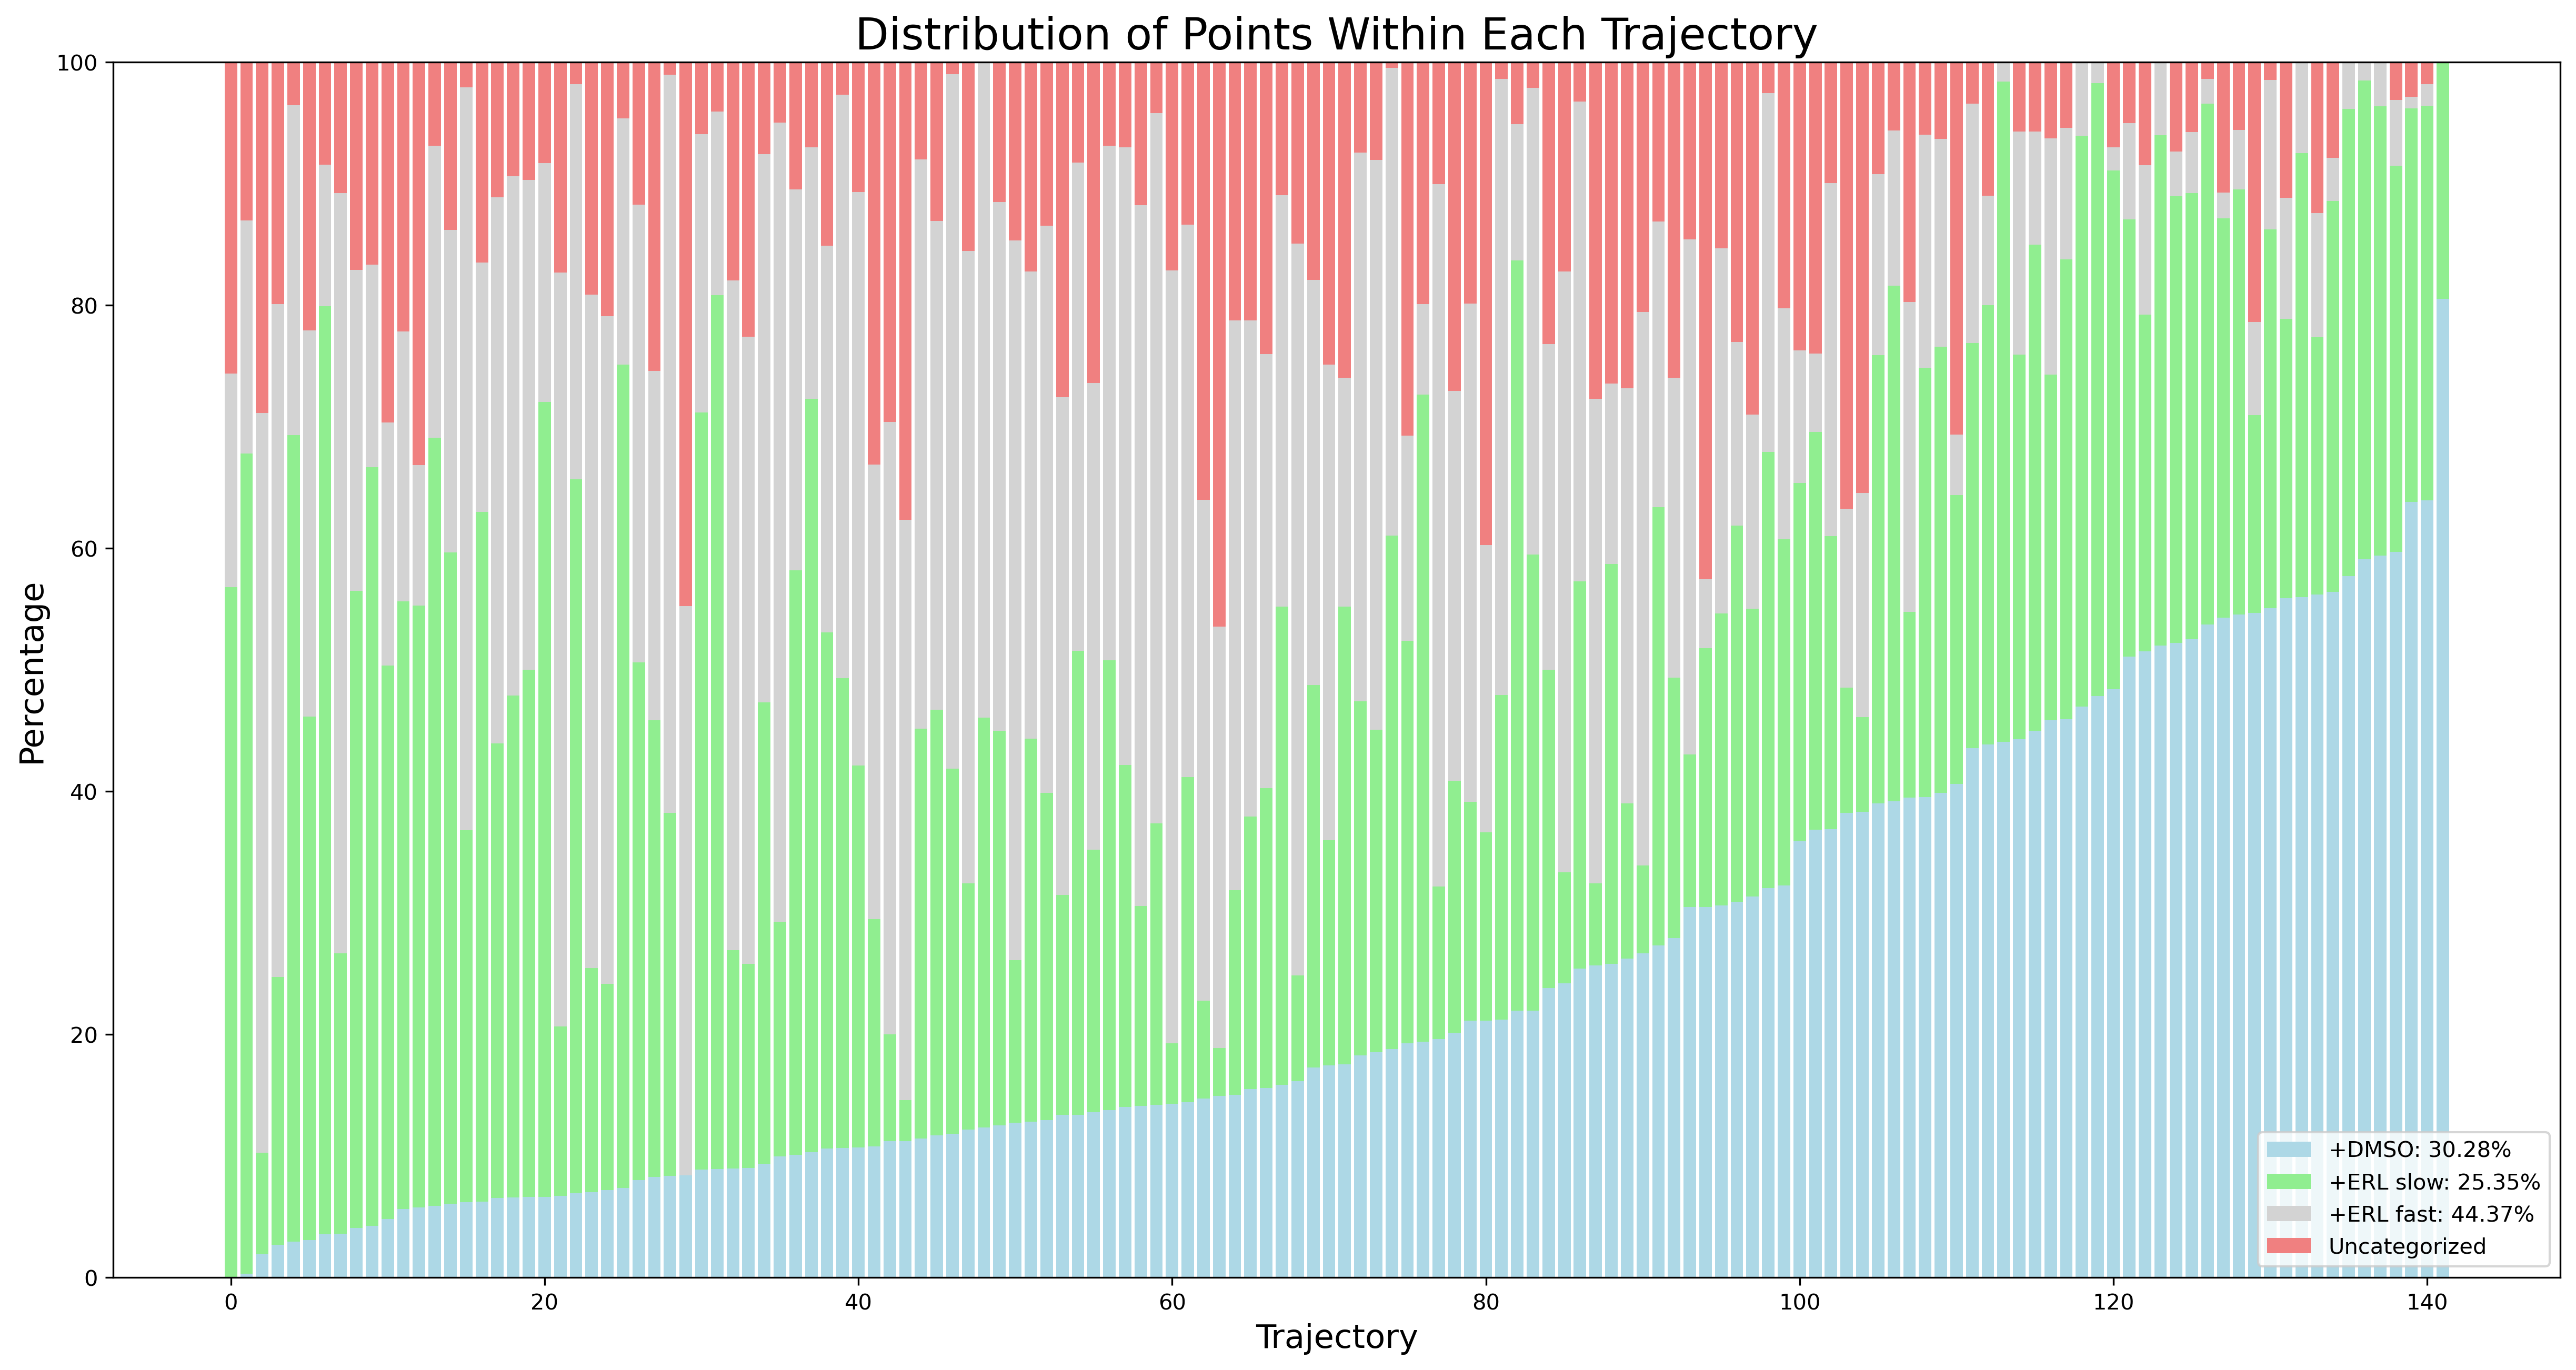

In [97]:
plt.figure(figsize=(20,10),dpi=300)

# create data
x = np.arange(sum(result_intstiff[0]))

y1 = np.zeros(len(result_intstiff[6]))
y2 = np.zeros(len(result_intstiff[6]))
y3 = np.zeros(len(result_intstiff[6]))
y4 = np.zeros(len(result_intstiff[6]))

for i in range(len(result_intstiff[6])):
    y1[i] = result_intstiff[6][i][2]
    y2[i] = result_intstiff[6][i][0]
    y3[i] = result_intstiff[6][i][1]
    y4[i] = result_intstiff[6][i][3]
    
inds = y1.argsort()
y1_sort = y1[inds]
y2_sort = y2[inds]
y3_sort = y3[inds]
y4_sort = y4[inds]
    
# plot bars in stack manner

plt.bar(x, y1_sort, color='lightblue')
plt.bar(x, y2_sort, bottom=y1_sort, color='lightgreen')
plt.bar(x, y3_sort, bottom=y1_sort+y2_sort, color='lightgrey')
plt.bar(x, y4_sort, bottom=y1_sort+y2_sort+y3_sort, color='lightcoral')

plt.xlabel("Trajectory", fontsize=15)
plt.ylabel("Percentage", fontsize=15)
plt.legend([f"+DMSO: {round(result_intstiff[7][2],2)}%", f"+ERL slow: {round(result_intstiff[7][0],2)}%", 
            f"+ERL fast: {round(result_intstiff[7][1],2)}%", "Uncategorized"])

plt.title("Distribution of Points Within Each Trajectory", fontsize=20)
plt.show()

##### Percentage of Points; Ordered by +ERL fast

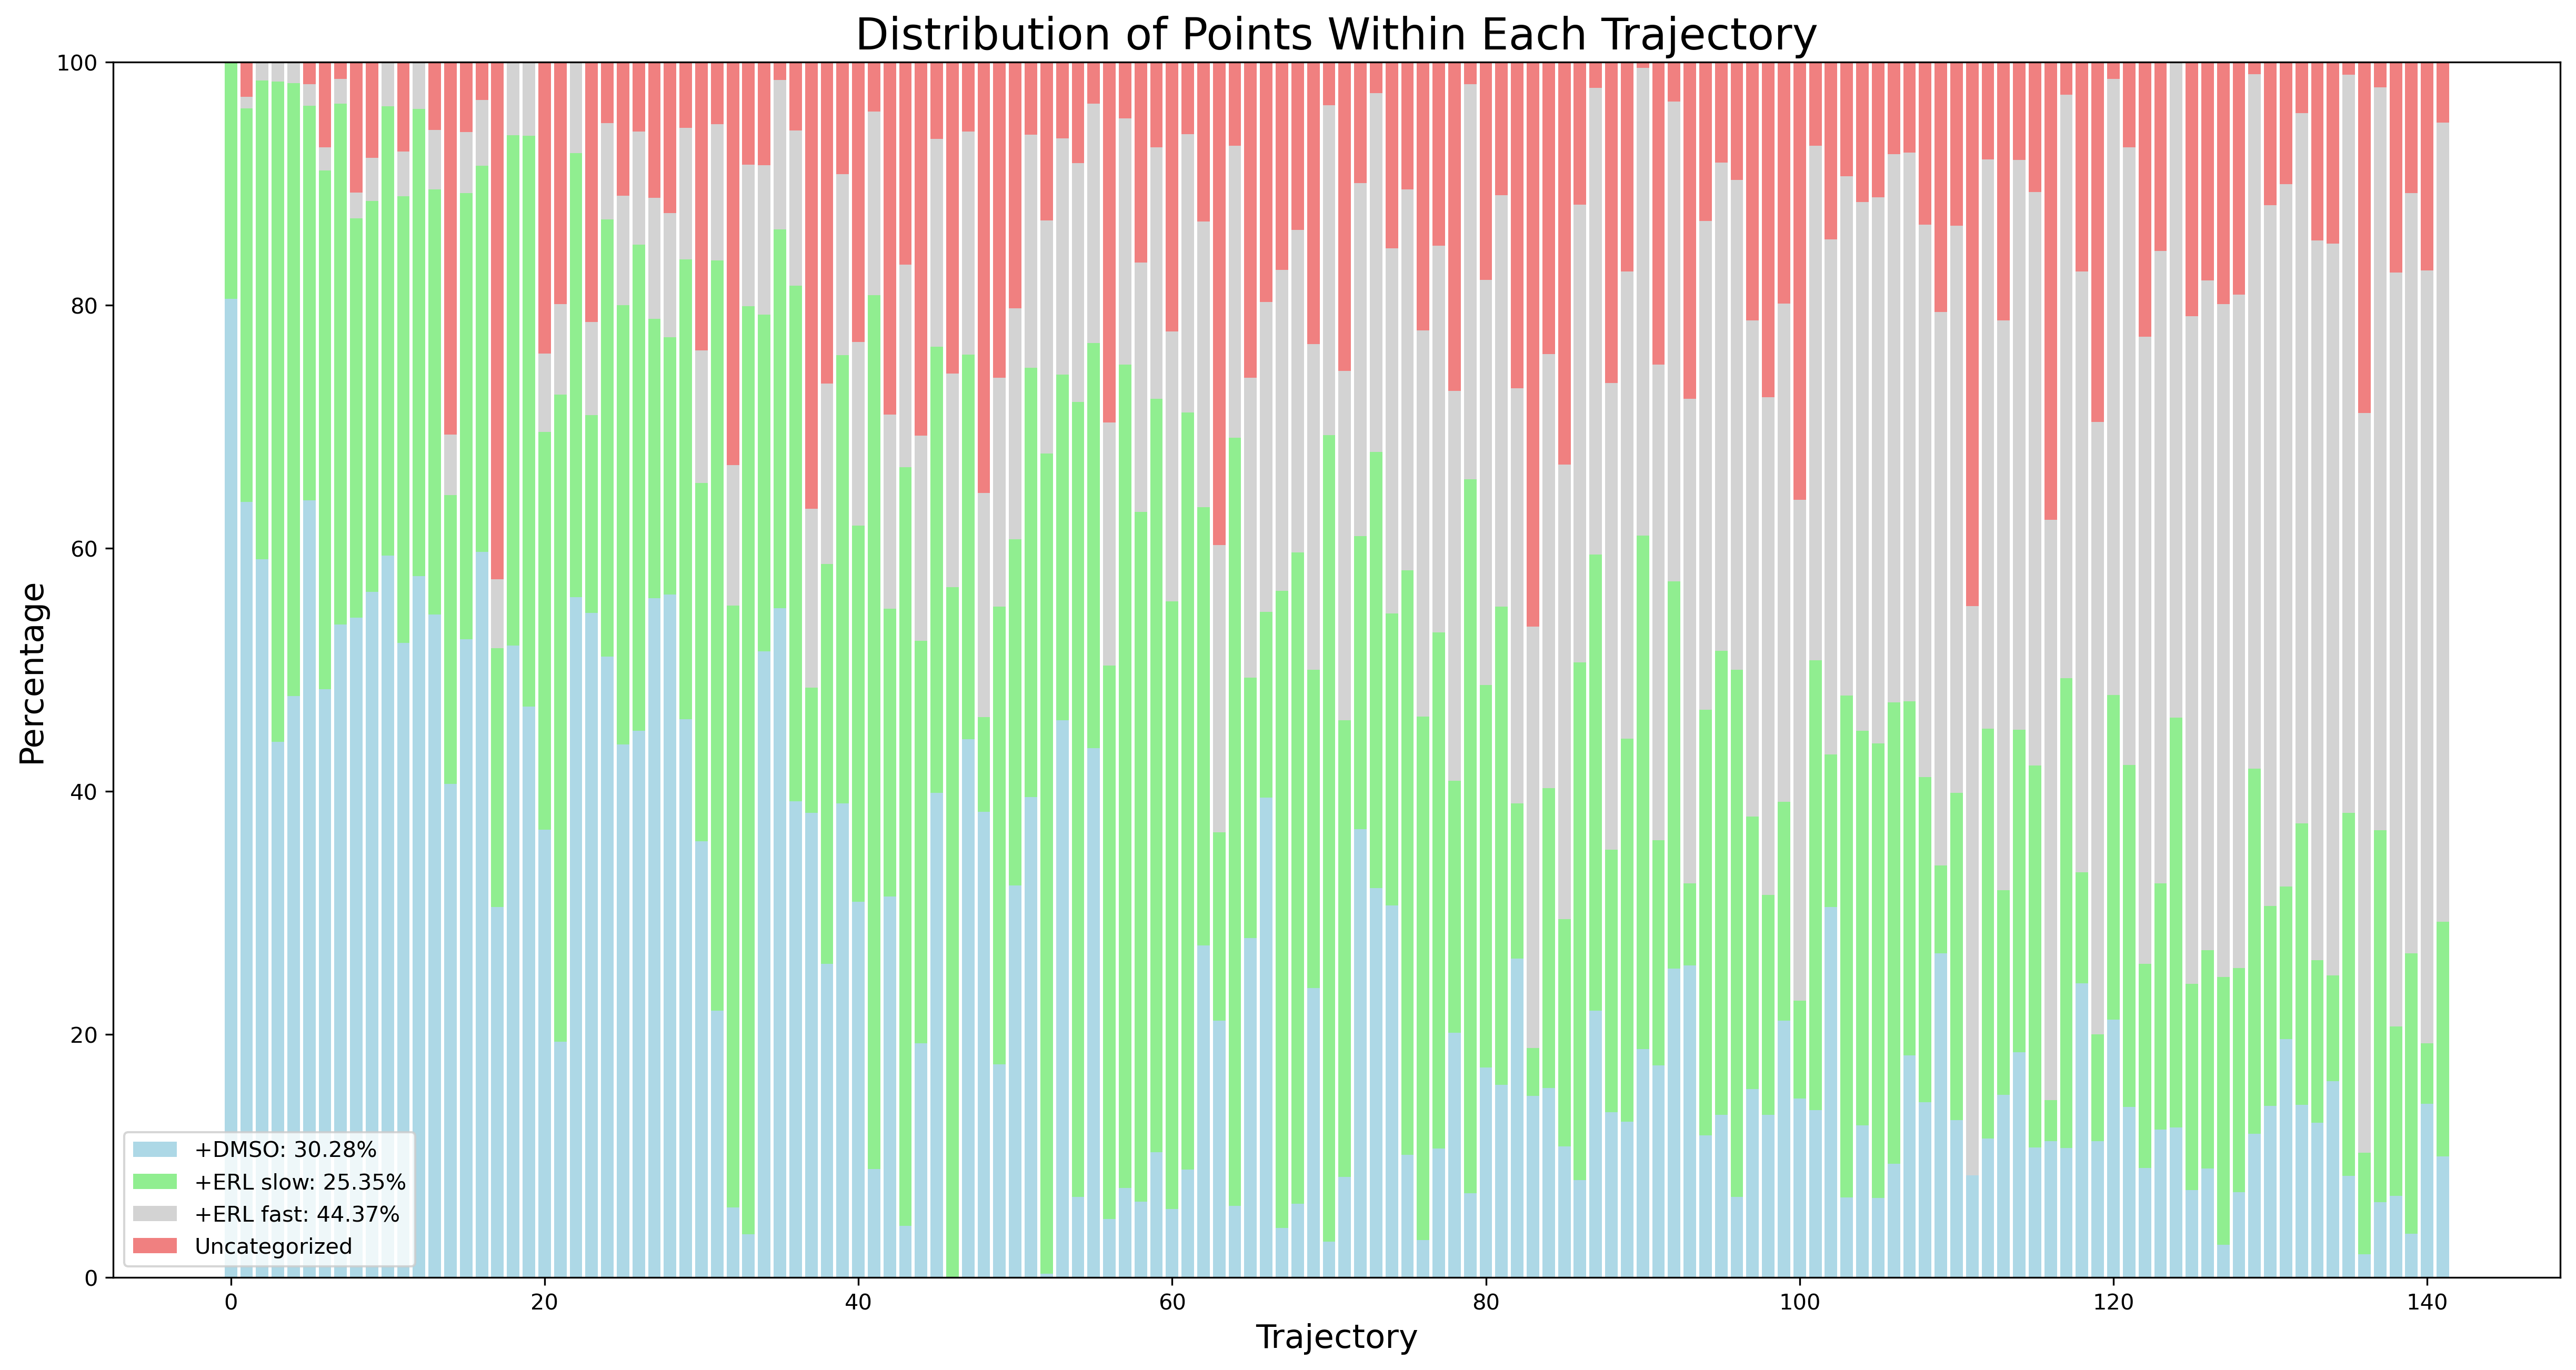

In [100]:
plt.figure(figsize=(20,10),dpi=300)

# create data
x = np.arange(sum(result_intstiff[0]))

y1 = np.zeros(len(result_intstiff[6]))
y2 = np.zeros(len(result_intstiff[6]))
y3 = np.zeros(len(result_intstiff[6]))
y4 = np.zeros(len(result_intstiff[6]))

for i in range(len(result_intstiff[6])):
    y1[i] = result_intstiff[6][i][2]
    y2[i] = result_intstiff[6][i][0]
    y3[i] = result_intstiff[6][i][1]
    y4[i] = result_intstiff[6][i][3]
    
inds = y3.argsort()
y1_sort = y1[inds]
y2_sort = y2[inds]
y3_sort = y3[inds]
y4_sort = y4[inds]
    
# plot bars in stack manner

plt.bar(x, y1_sort, color='lightblue')
plt.bar(x, y2_sort, bottom=y1_sort, color='lightgreen')
plt.bar(x, y3_sort, bottom=y1_sort+y2_sort, color='lightgrey')
plt.bar(x, y4_sort, bottom=y1_sort+y2_sort+y3_sort, color='lightcoral')

plt.xlabel("Trajectory", fontsize=15)
plt.ylabel("Percentage", fontsize=15)
plt.legend([f"+DMSO: {round(result_intstiff[7][2],2)}%", f"+ERL slow: {round(result_intstiff[7][0],2)}%", 
            f"+ERL fast: {round(result_intstiff[7][1],2)}%", "Uncategorized"])

plt.title("Distribution of Points Within Each Trajectory", fontsize=20)
plt.show()

### Histogram: How many trajectories have a certain percentage of point left uncategorized?

In [132]:
# plt.hist(result_intstiff[1])
# plt.xlabel('Percentage of Points Uncategorized')
# plt.ylabel('Number of Trajectories')

## High Stiffness Results

### UMAP Plot

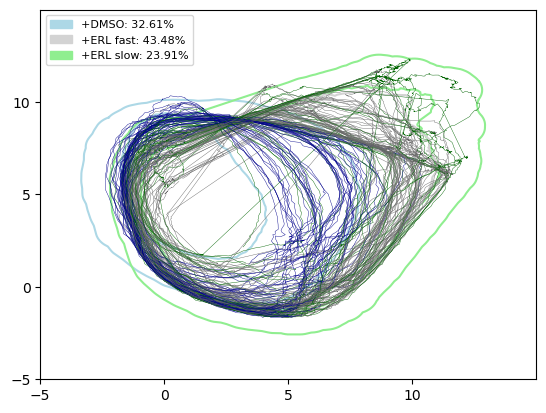

In [83]:
result_highstiff = plot_by_class(umap_all_erl_3_1)

### Stacked Bar Plot: Distribution of Points for Each Trajectory

##### Number of Points; Unordered

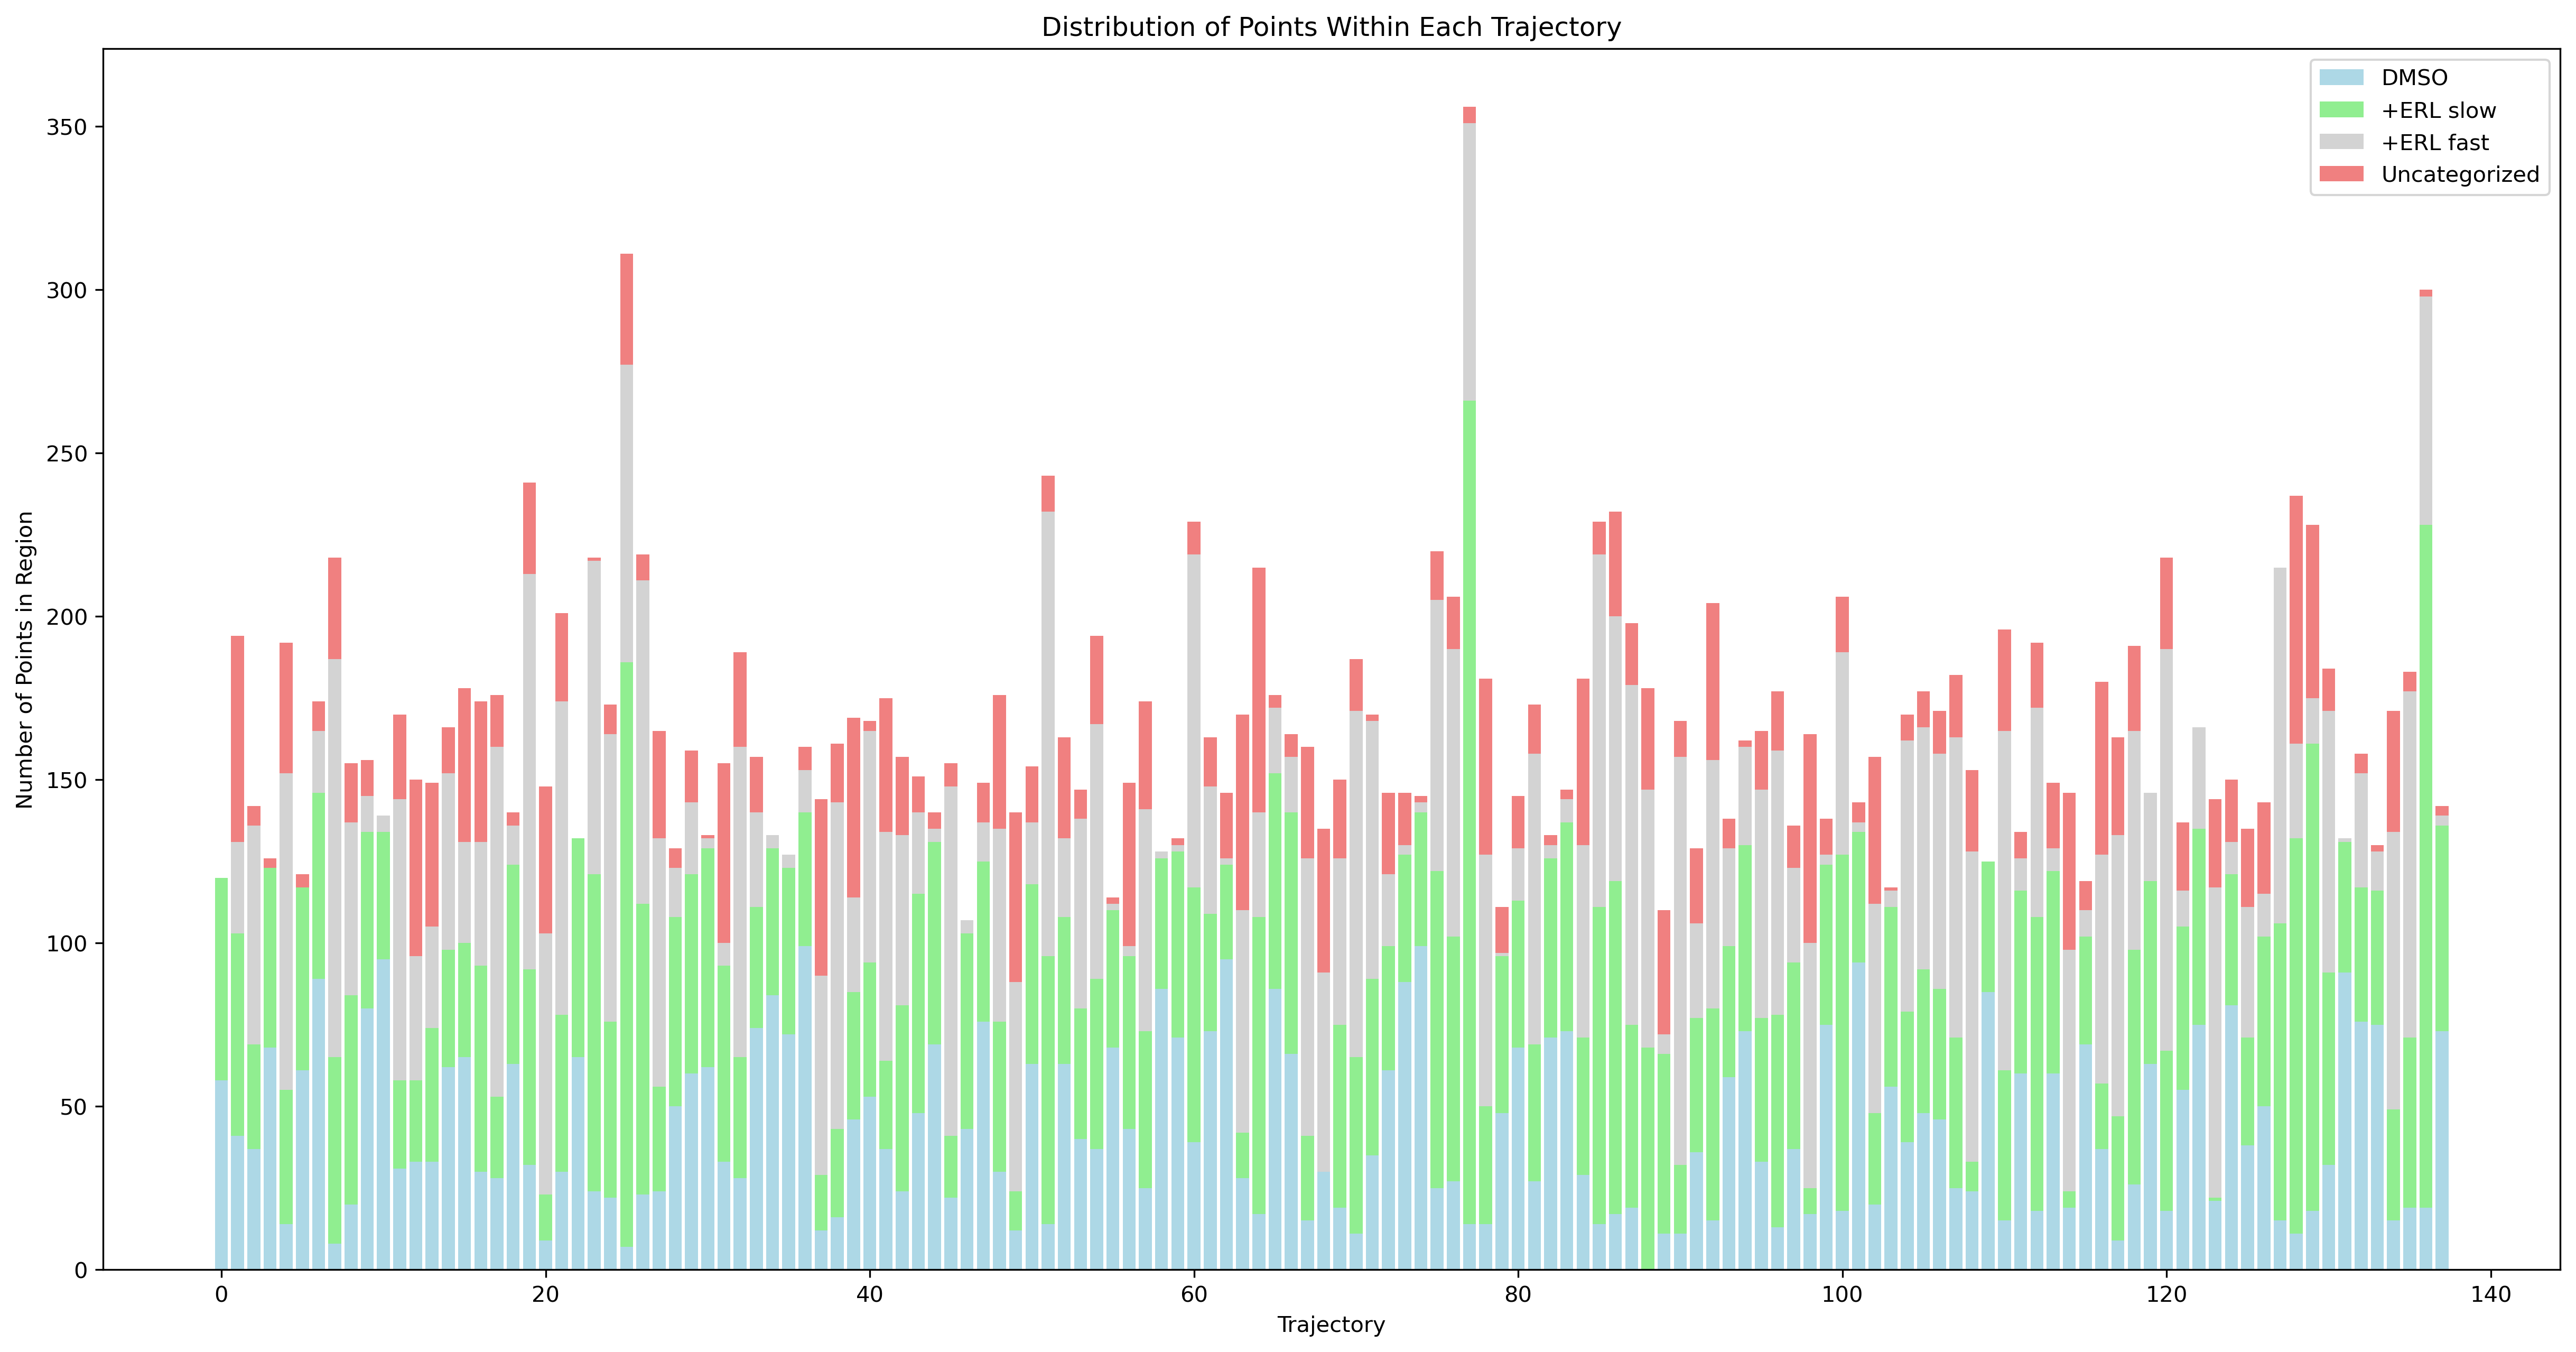

In [85]:
plt.figure(figsize=(20,10),dpi=300)

# create data
x = np.arange(sum(result_highstiff[0]))

y1 = np.array(result_highstiff[2])
y2 = np.array(result_highstiff[3])
y3 = np.array(result_highstiff[4])
y4 = np.array(result_highstiff[5])
 
# plot bars in stack manner
plt.bar(x, y1, color='lightblue')
plt.bar(x, y2, bottom=y1, color='lightgreen')
plt.bar(x, y3, bottom=y1+y2, color='lightgrey')
plt.bar(x, y4, bottom=y1+y2+y3, color='lightcoral')

plt.xlabel("Trajectory")
plt.ylabel("Number of Points in Region")
plt.legend(["DMSO", "+ERL slow", "+ERL fast", "Uncategorized"])
plt.title("Distribution of Points Within Each Trajectory")
plt.show()

##### Percentage of Points; Ordered by +DMSO

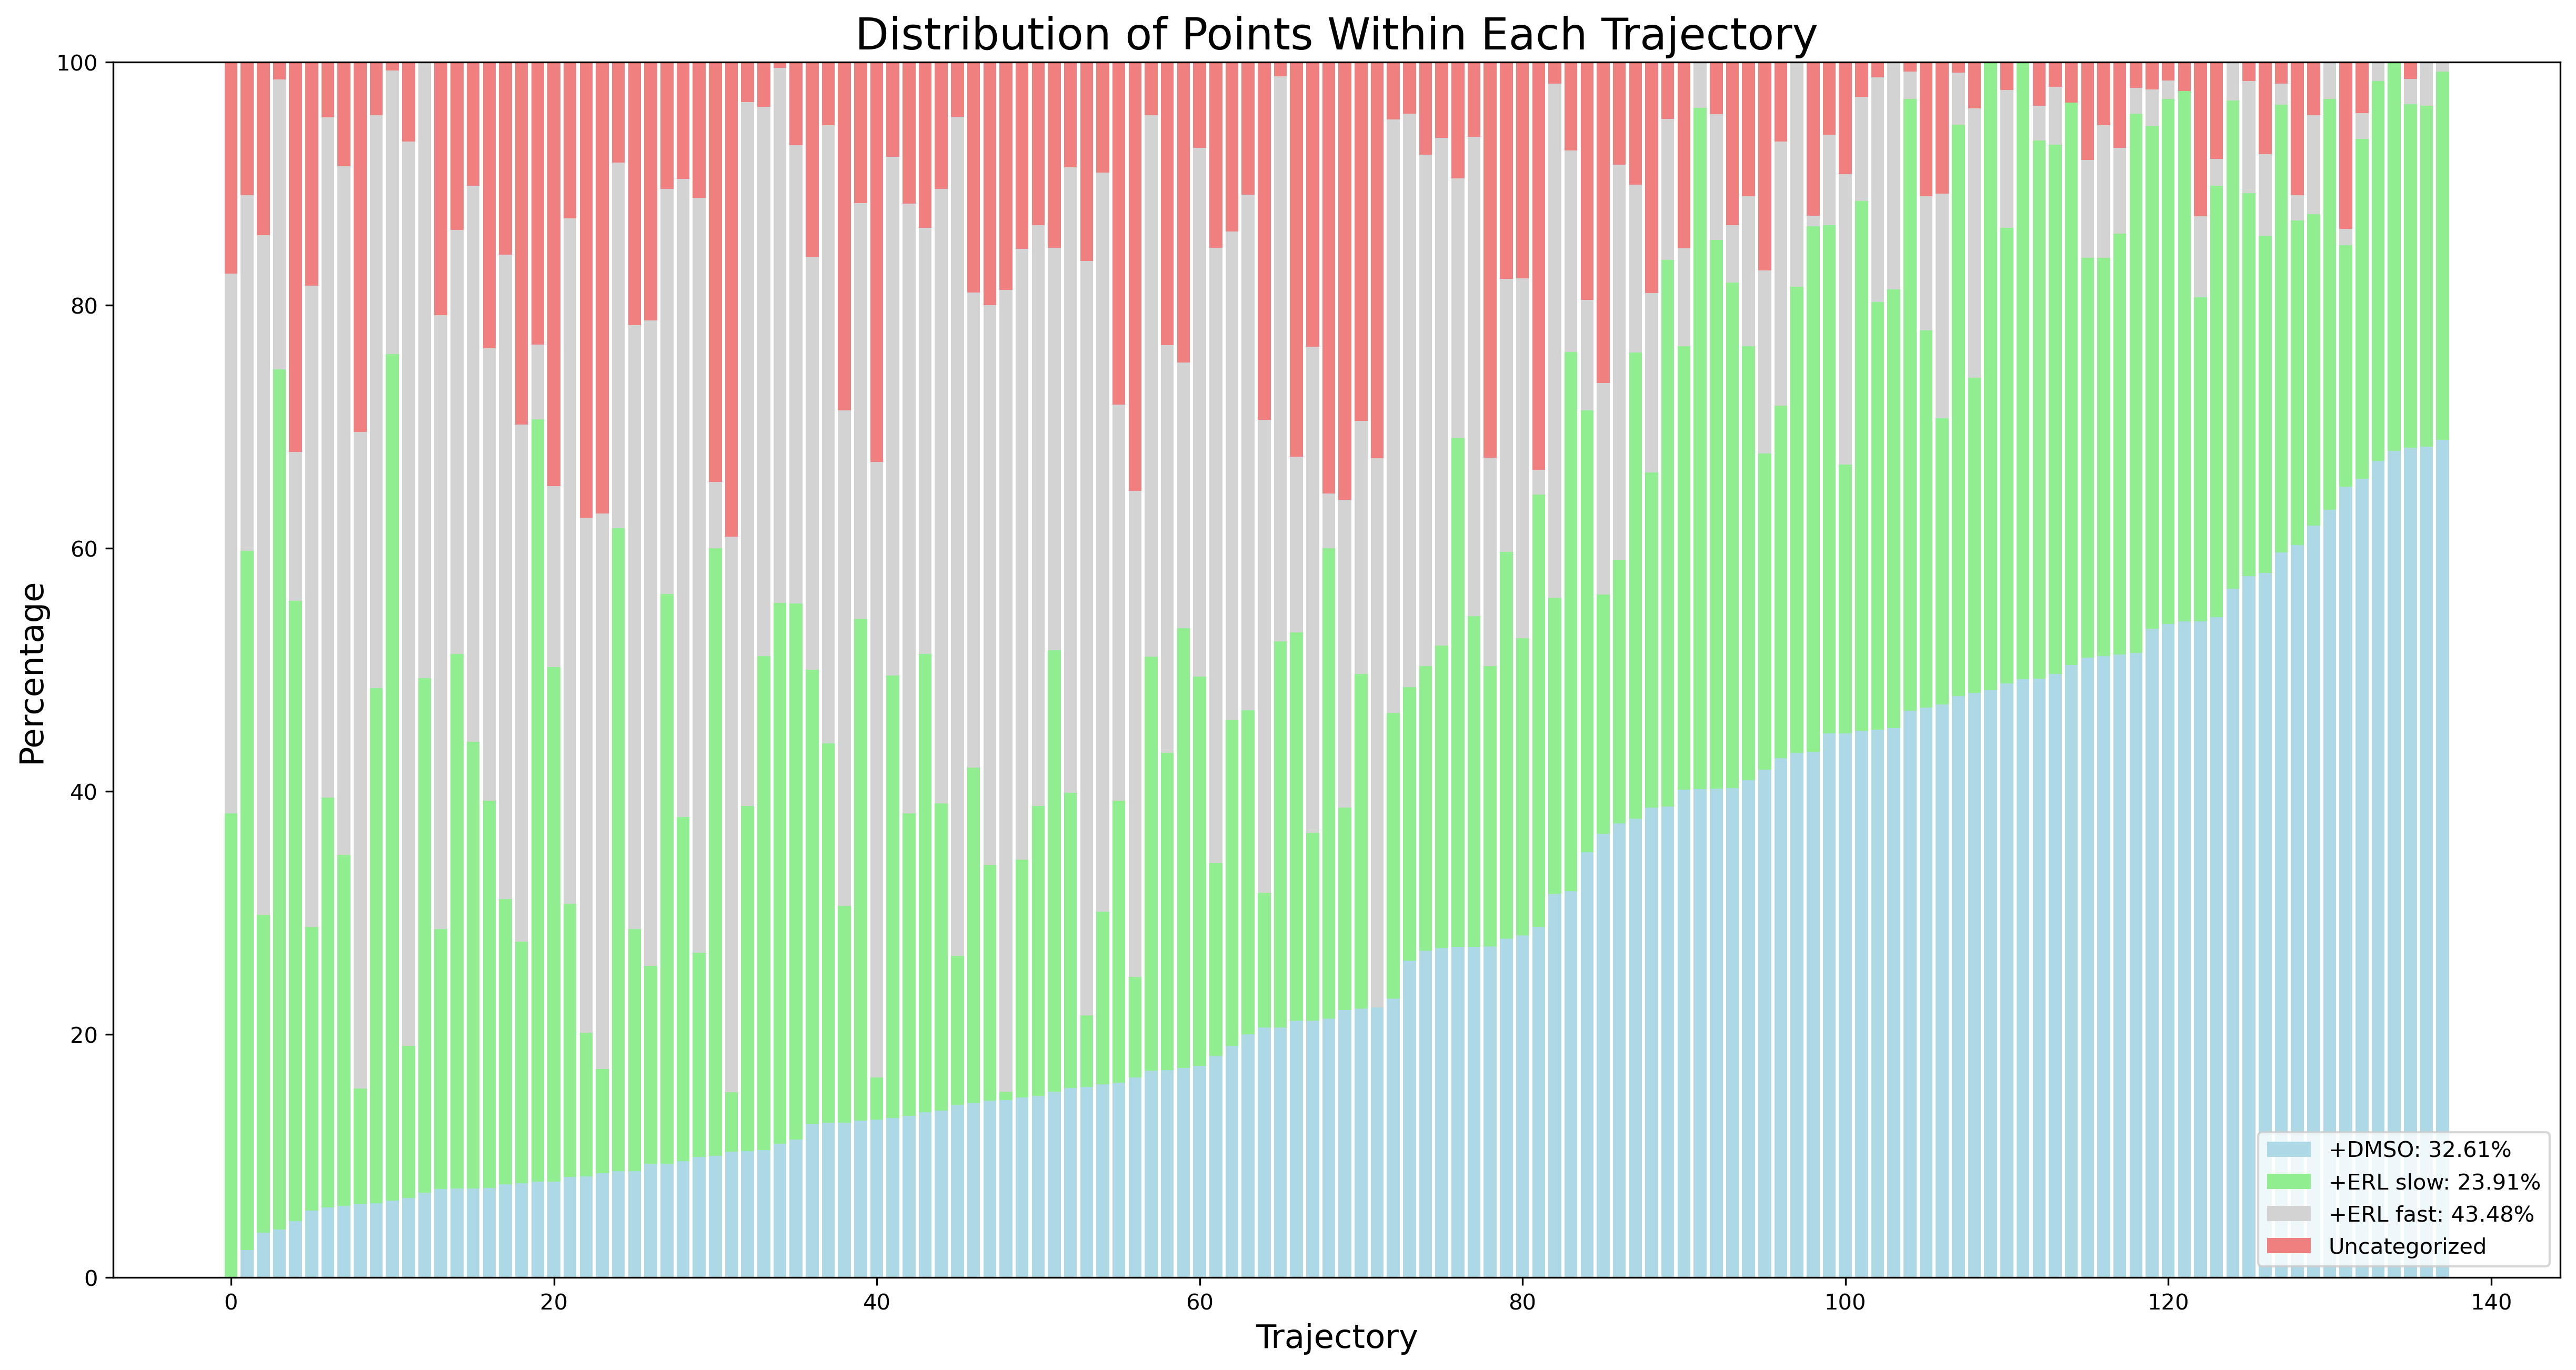

In [95]:
plt.figure(figsize=(20,10),dpi=300)

# create data
x = np.arange(sum(result_highstiff[0]))

y1 = np.zeros(len(result_highstiff[6]))
y2 = np.zeros(len(result_highstiff[6]))
y3 = np.zeros(len(result_highstiff[6]))
y4 = np.zeros(len(result_highstiff[6]))

for i in range(len(result_highstiff[6])):
    y1[i] = result_highstiff[6][i][2]
    y2[i] = result_highstiff[6][i][0]
    y3[i] = result_highstiff[6][i][1]
    y4[i] = result_highstiff[6][i][3]
    
inds = y1.argsort()
y1_sort = y1[inds]
y2_sort = y2[inds]
y3_sort = y3[inds]
y4_sort = y4[inds]
    
# plot bars in stack manner

plt.bar(x, y1_sort, color='lightblue')
plt.bar(x, y2_sort, bottom=y1_sort, color='lightgreen')
plt.bar(x, y3_sort, bottom=y1_sort+y2_sort, color='lightgrey')
plt.bar(x, y4_sort, bottom=y1_sort+y2_sort+y3_sort, color='lightcoral')

plt.xlabel("Trajectory", fontsize=15)
plt.ylabel("Percentage", fontsize=15)
plt.legend([f"+DMSO: {round(result_highstiff[7][2],2)}%", f"+ERL slow: {round(result_highstiff[7][0],2)}%", 
            f"+ERL fast: {round(result_highstiff[7][1],2)}%", "Uncategorized"])

plt.title("Distribution of Points Within Each Trajectory", fontsize=20)
plt.show()

##### Percentage of Points; Ordered by +ERL fast

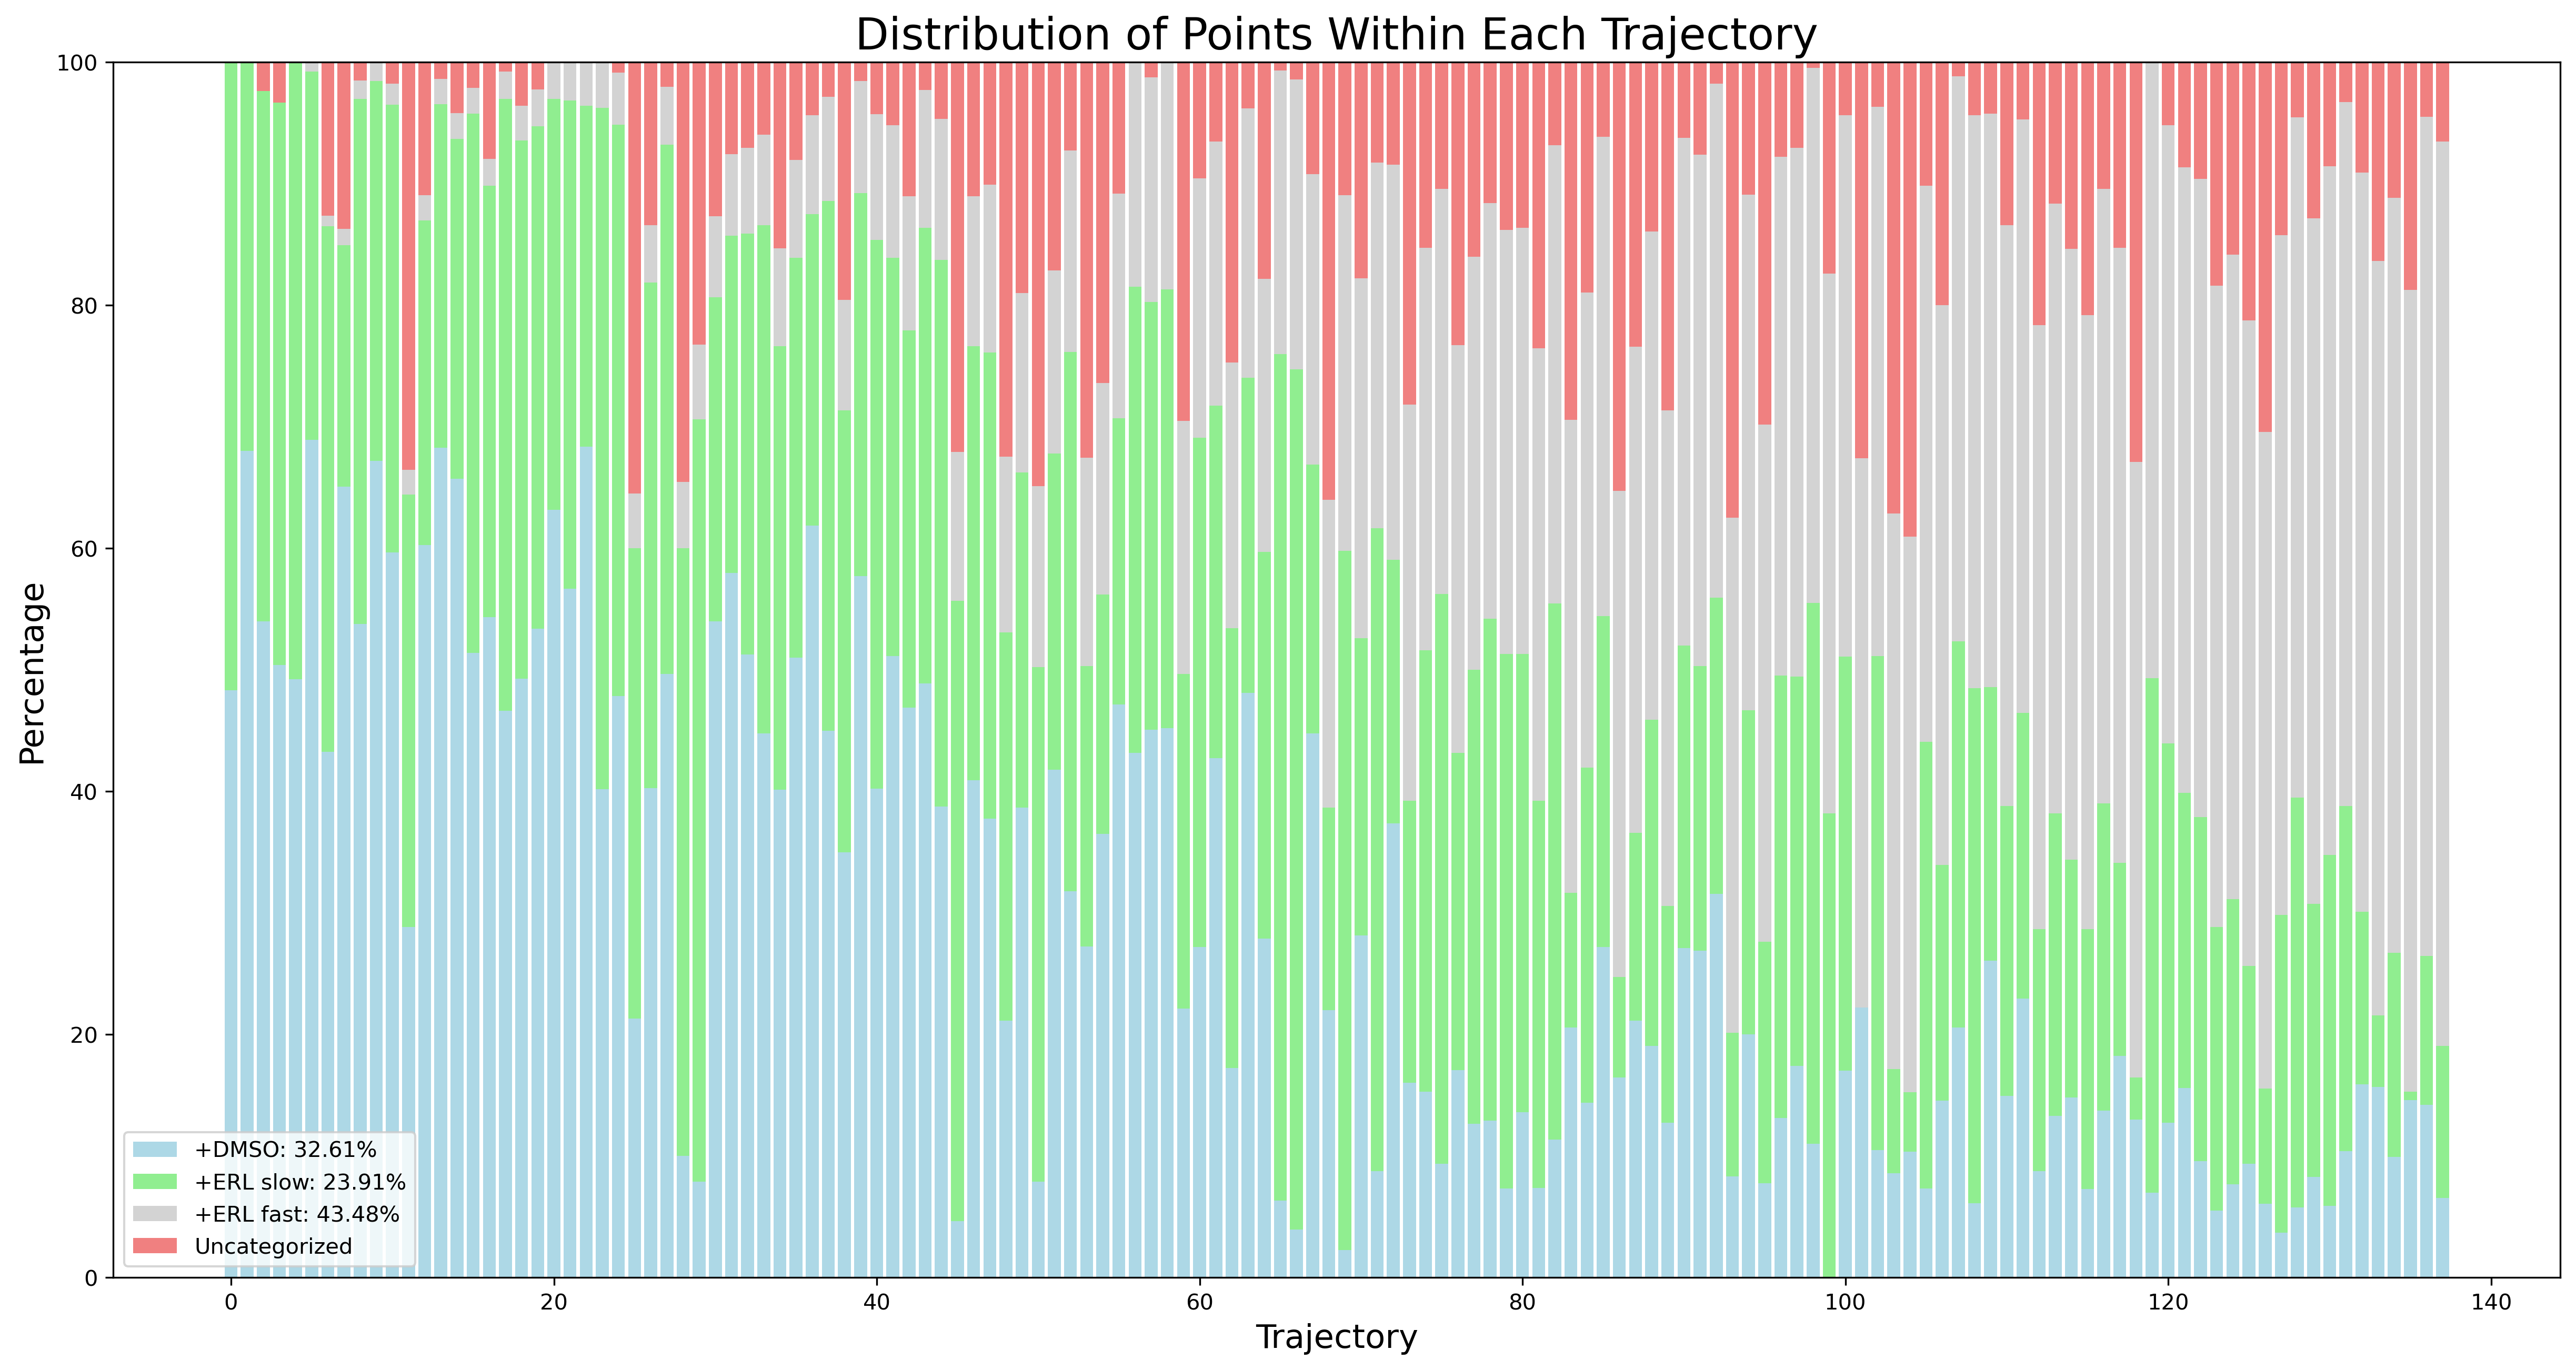

In [94]:
plt.figure(figsize=(20,10),dpi=300)

# create data
x = np.arange(sum(result_highstiff[0]))

y1 = np.zeros(len(result_highstiff[6]))
y2 = np.zeros(len(result_highstiff[6]))
y3 = np.zeros(len(result_highstiff[6]))
y4 = np.zeros(len(result_highstiff[6]))

for i in range(len(result_highstiff[6])):
    y1[i] = result_highstiff[6][i][2]
    y2[i] = result_highstiff[6][i][0]
    y3[i] = result_highstiff[6][i][1]
    y4[i] = result_highstiff[6][i][3]
    
inds = y3.argsort()
y1_sort = y1[inds]
y2_sort = y2[inds]
y3_sort = y3[inds]
y4_sort = y4[inds]
    
# plot bars in stack manner

plt.bar(x, y1_sort, color='lightblue')
plt.bar(x, y2_sort, bottom=y1_sort, color='lightgreen')
plt.bar(x, y3_sort, bottom=y1_sort+y2_sort, color='lightgrey')
plt.bar(x, y4_sort, bottom=y1_sort+y2_sort+y3_sort, color='lightcoral')

plt.xlabel("Trajectory", fontsize=15)
plt.ylabel("Percentage", fontsize=15)
plt.legend([f"+DMSO: {round(result_highstiff[7][2],2)}%", f"+ERL slow: {round(result_highstiff[7][0],2)}%", 
            f"+ERL fast: {round(result_highstiff[7][1],2)}%", "Uncategorized"])

plt.title("Distribution of Points Within Each Trajectory", fontsize=20)
plt.show()

### Histogram: How many trajectories have a certain percentage of point left uncategorized?

In [133]:
# plt.hist(result_highstiff[1])
# plt.xlabel('Percentage of Points Uncategorized')
# plt.ylabel('Number of Trajectories')